**step 1 : we are importing the csv and txt files to the drive and taking from that**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
os.listdir('/content/drive/MyDrive/aml_data')  # confirms your files are there and named correctly

['HI-Small_Patterns.txt',
 'HI-Small_Trans.csv',
 'HI-Small_accounts.csv',
 'sample_neighborhood.png',
 'HI-Small_communities.pkl',
 'HI-Small_merged_timeline.parquet',
 'HI-Small_agg_graph.graphml',
 'sample_longer_cycle.png',
 'sample_cycle.png',
 'community_1115_laundering_focus.png',
 'step4_roc_pr_curves.png',
 'step4_feature_importance.png',
 'HI-Small_risk_scores.csv',
 'HI-Small_rf_model.pkl',
 'iso_forest_vs_rf_comparison.png',
 'HI-Small_isolation_forest_results.csv',
 'HI-Small_full_graph_validation.csv',
 'full_graph_native_roc.png',
 'full_graph_native_feature_importance.png',
 'HI-Small_rf_model_fullgraph.pkl',
 'model_comparison.png',
 'HI-Small_model_comparison.csv',
 'shap_summary_plot.png',
 'shap_force_plot_top_account.png',
 'HI-Small_shap_values_sample.csv',
 'HI-Small_streaming_sample.csv']

**step 2 : we are checking for the column names of transactions and accounts and shape of both**

In [ ]:
import pandas as pd

trans = pd.read_csv('/content/drive/MyDrive/aml_data/HI-Small_Trans.csv')
accounts = pd.read_csv('/content/drive/MyDrive/aml_data/HI-Small_accounts.csv')

print("TRANS shape:", trans.shape)
print("TRANS columns:", trans.columns.tolist())
print(trans.head())
print()
print("ACCOUNTS shape:", accounts.shape)
print("ACCOUNTS columns:", accounts.columns.tolist())
print(accounts.head())
print()
with open('/content/drive/MyDrive/aml_data/HI-Small_Patterns.txt') as f:
    print(f.read()[:1000])

TRANS shape: (5078345, 11)
TRANS columns: ['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering']
          Timestamp  From Bank    Account  To Bank  Account.1  \
0  2022/09/01 00:20         10  8000EBD30       10  8000EBD30   
1  2022/09/01 00:20       3208  8000F4580        1  8000F5340   
2  2022/09/01 00:00       3209  8000F4670     3209  8000F4670   
3  2022/09/01 00:02         12  8000F5030       12  8000F5030   
4  2022/09/01 00:06         10  8000F5200       10  8000F5200   

   Amount Received Receiving Currency  Amount Paid Payment Currency  \
0          3697.34          US Dollar      3697.34        US Dollar   
1             0.01          US Dollar         0.01        US Dollar   
2         14675.57          US Dollar     14675.57        US Dollar   
3          2806.97          US Dollar      2806.97        US Dollar   
4         36682.97          US Dollar  

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

DATA_DIR = '/content/drive/MyDrive/aml_data'

trans = pd.read_csv(f'{DATA_DIR}/HI-Small_Trans.csv')
accounts = pd.read_csv(f'{DATA_DIR}/HI-Small_accounts.csv')

print('Trans:', trans.shape)
print('Accounts:', accounts.shape)
trans.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Trans: (5078345, 11)
Accounts: (518581, 5)


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 00:20,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022/09/01 00:20,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022/09/01 00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022/09/01 00:02,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022/09/01 00:06,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0


## Step 3 : Basic cleaning

- Parse `Timestamp` into a real datetime column.
- Standardize column names (spaces -> underscores) so they're easier to work with in code.
- Check for and report nulls/duplicates before dropping anything

In [ ]:
trans.columns = [c.strip().replace(' ', '_') for c in trans.columns]
accounts.columns = [c.strip().replace(' ', '_') for c in accounts.columns]

trans['Timestamp'] = pd.to_datetime(trans['Timestamp'], format='%Y/%m/%d %H:%M')

print('Null counts (trans):')
print(trans.isnull().sum())
print()
print('Null counts (accounts):')
print(accounts.isnull().sum())
print()
print('Duplicate transaction rows:', trans.duplicated().sum())
print('Duplicate account rows:', accounts.duplicated().sum())


Null counts (trans):
Timestamp             0
From_Bank             0
Account               0
To_Bank               0
Account.1             0
Amount_Received       0
Receiving_Currency    0
Amount_Paid           0
Payment_Currency      0
Payment_Format        0
Is_Laundering         0
dtype: int64

Null counts (accounts):
Bank_Name         0
Bank_ID           0
Account_Number    0
Entity_ID         0
Entity_Name       0
dtype: int64

Duplicate transaction rows: 9
Duplicate account rows: 0


In [ ]:
# Drop exact duplicate rows only (safe — doesn't touch legitimate repeated transactions
# between the same accounts, since a duplicate here means every column matches exactly)
trans = trans.drop_duplicates().reset_index(drop=True)
accounts = accounts.drop_duplicates().reset_index(drop=True)

print('After dedup — Trans:', trans.shape, '| Accounts:', accounts.shape)


After dedup — Trans: (5078336, 11) | Accounts: (518581, 5)


**Step 4 :  Merge account metadata onto the transaction timeline**

In [ ]:
# Sender-side merge
merged = trans.merge(
    accounts.add_prefix('Sender_'),
    left_on='Account', right_on='Sender_Account_Number',
    how='left'
)

# Receiver-side merge
merged = merged.merge(
    accounts.add_prefix('Receiver_'),
    left_on='Account.1', right_on='Receiver_Account_Number',
    how='left'
)

print('Merged shape:', merged.shape)
missing_sender = merged['Sender_Entity_ID'].isnull().sum()
missing_receiver = merged['Receiver_Entity_ID'].isnull().sum()
print(f'Transactions with no matching sender account: {missing_sender} ({missing_sender/len(merged):.2%})')
print(f'Transactions with no matching receiver account: {missing_receiver} ({missing_receiver/len(merged):.2%})')

merged.head()


Merged shape: (5078406, 21)
Transactions with no matching sender account: 0 (0.00%)
Transactions with no matching receiver account: 0 (0.00%)


,Timestamp,From_Bank,Account,To_Bank,Account.1,Amount_Received,Receiving_Currency,Amount_Paid,Payment_Currency,Payment_Format,...,Sender_Bank_Name,Sender_Bank_ID,Sender_Account_Number,Sender_Entity_ID,Sender_Entity_Name,Receiver_Bank_Name,Receiver_Bank_ID,Receiver_Account_Number,Receiver_Entity_ID,Receiver_Entity_Name
0,2022-09-01 00:20:00,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,...,National Bank of Laramie,10,8000EBD30,800D232D0,Partnership #1,National Bank of Laramie,10,8000EBD30,800D232D0,Partnership #1
1,2022-09-01 00:20:00,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,...,Sappo Cooperative Bank,3208,8000F4580,8008EEA70,Partnership #2,Arbor Savings Bank,1,8000F5340,800AA5D20,Corporation #1
2,2022-09-01 00:00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,...,National Bank of Fort Wayne,3209,8000F4670,800FBB3A0,Partnership #3,National Bank of Fort Wayne,3209,8000F4670,800FBB3A0,Partnership #3
3,2022-09-01 00:02:00,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,...,National Bank of the East,12,8000F5030,800C0EF20,Sole Proprietorship #1,National Bank of the East,12,8000F5030,800C0EF20,Sole Proprietorship #1
4,2022-09-01 00:06:00,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,...,National Bank of Laramie,10,8000F5200,800C3EC10,Partnership #4,National Bank of Laramie,10,8000F5200,800C3EC10,Partnership #4


In [ ]:
merged = merged.sort_values('Timestamp').reset_index(drop=True)
merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5078406 entries, 0 to 5078405
Data columns (total 21 columns):
 #   Column                   Dtype         
---  ------                   -----         
 0   Timestamp                datetime64[ns]
 1   From_Bank                int64         
 2   Account                  object        
 3   To_Bank                  int64         
 4   Account.1                object        
 5   Amount_Received          float64       
 6   Receiving_Currency       object        
 7   Amount_Paid              float64       
 8   Payment_Currency         object        
 9   Payment_Format           object        
 10  Is_Laundering            int64         
 11  Sender_Bank_Name         object        
 12  Sender_Bank_ID           int64         
 13  Sender_Account_Number    object        
 14  Sender_Entity_ID         object        
 15  Sender_Entity_Name       object        
 16  Receiver_Bank_Name       object        
 17  Receiver_Bank_ID         in

Step 5 :  Quick sanity checks on the label

Confirm the `Is_Laundering` label distribution — this dataset is intentionally imbalanced,
so knowing the exact ratio now matters for how you evaluate models later.

In [ ]:
label_counts = merged['Is_Laundering'].value_counts()
print(label_counts)
print(f"Laundering ratio: {label_counts.get(1, 0) / len(merged):.4%}")


Is_Laundering
0    5073229
1       5177
Name: count, dtype: int64
Laundering ratio: 0.1019%


In [ ]:
# Re-do the merges using (Bank_ID, Account_Number) as the composite key —
# this matches how AMLSim actually assigns account numbers (unique per bank, not globally)

accounts_keyed = accounts.copy()
accounts_keyed['_key'] = accounts_keyed['Bank_ID'].astype(str) + '_' + accounts_keyed['Account_Number']

trans['_sender_key'] = trans['From_Bank'].astype(str) + '_' + trans['Account']
trans['_receiver_key'] = trans['To_Bank'].astype(str) + '_' + trans['Account.1']

merged = trans.merge(
    accounts_keyed.add_prefix('Sender_'),
    left_on='_sender_key', right_on='Sender__key',
    how='left'
).merge(
    accounts_keyed.add_prefix('Receiver_'),
    left_on='_receiver_key', right_on='Receiver__key',
    how='left'
)

merged = merged.drop(columns=['_sender_key', '_receiver_key', 'Sender__key', 'Receiver__key'])

print('Merged shape:', merged.shape)  # should now equal 5,078,336 exactly
print('Any row multiplication?', merged.shape[0] != trans.shape[0])

Merged shape: (5078336, 21)
Any row multiplication? False


Step 6 :  Save the cleaned/merged timeline

Save back to Drive so Step 2 (graph construction) can load this directly instead of
re-running the merge every session.


In [ ]:
merged = merged.sort_values('Timestamp').reset_index(drop=True)
OUT_PATH = f'{DATA_DIR}/HI-Small_merged_timeline.parquet'
merged.to_parquet(OUT_PATH, index=False)
print('Saved to', OUT_PATH)

Saved to /content/drive/MyDrive/aml_data/HI-Small_merged_timeline.parquet


**Graph construction**

**## 1. Load the cleaned timeline from Step 1

1. **Full transaction graph** — every transaction is its own edge (accurate, but heavy:
   ~5M edges). Useful when you need exact transaction-level detail (e.g. validating a
   specific laundering pattern from `Patterns.txt`).
2. **Aggregated account-pair graph** — one edge per unique (sender, receiver) pair, with
   transaction count, total amount, and an `any_laundering` flag as edge attributes. This
   is dramatically smaller and is what you'll actually run centrality / community detection
   on in Step 3 — Colab's free tier will struggle with graph algorithms on 5M raw edges.

Both are saved to Drive so you don't have to rebuild them every session.**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import networkx as nx

DATA_DIR = '/content/drive/MyDrive/aml_data'
merged = pd.read_parquet(f'{DATA_DIR}/HI-Small_merged_timeline.parquet')

print('Loaded:', merged.shape)
merged.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded: (5078336, 21)


,Timestamp,From_Bank,Account,To_Bank,Account.1,Amount_Received,Receiving_Currency,Amount_Paid,Payment_Currency,Payment_Format,...,Sender_Bank_Name,Sender_Bank_ID,Sender_Account_Number,Sender_Entity_ID,Sender_Entity_Name,Receiver_Bank_Name,Receiver_Bank_ID,Receiver_Account_Number,Receiver_Entity_ID,Receiver_Entity_Name
0,2022-09-01,32282,801B64CE0,32282,801B64CE0,29294.03,US Dollar,29294.03,US Dollar,Reinvestment,...,First Bank of Houston,32282,801B64CE0,800E5A7A0,Sole Proprietorship #4172,First Bank of Houston,32282,801B64CE0,800E5A7A0,Sole Proprietorship #4172
1,2022-09-01,212818,804B1DF50,212818,804B1DF50,538528.53,Rupee,538528.53,Rupee,Reinvestment,...,India Bank #30,212818,804B1DF50,800ABA660,Partnership #32618,India Bank #30,212818,804B1DF50,800ABA660,Partnership #32618
2,2022-09-01,16927,8062913A0,28,806291440,96718657.00,Ruble,96718657.00,Ruble,ACH,...,Russia Bank #21,16927,8062913A0,800B7E980,Partnership #34005,Australia Bank #0,28,806291440,800B55350,Partnership #33832
3,2022-09-01,131086,80CB3F220,131086,80CB3F220,20289185.18,Mexican Peso,20289185.18,Mexican Peso,Reinvestment,...,Mexico Bank #18,131086,80CB3F220,800D50000,Sole Proprietorship #36252,Mexico Bank #18,131086,80CB3F220,800D50000,Sole Proprietorship #36252
4,2022-09-01,1068,802AC9790,17425,80EC2E740,3174.84,US Dollar,3174.84,US Dollar,Cheque,...,National Bank of Detroit,1068,802AC9790,80087E1B0,Corporation #16063,Baltech Thrift,17425,80EC2E740,800F0A530,Sole Proprietorship #2685


## 2. Build the aggregated account-pair graph (build this first — it's what you'll use most)

Nodes = accounts (using the combined `Bank_ID_Account` key, since account numbers repeat
across banks). Edges = one per unique sender→receiver pair, with:
- `n_transactions`: how many times money moved sender→receiver
- `total_amount`: sum of `Amount_Paid` across all those transactions
- `any_laundering`: 1 if *any* transaction on this edge was flagged `Is_Laundering`
- `laundering_count`: how many of the transactions were flagged


In [ ]:
merged['sender_node'] = merged['From_Bank'].astype(str) + '_' + merged['Account']
merged['receiver_node'] = merged['To_Bank'].astype(str) + '_' + merged['Account.1']

agg = merged.groupby(['sender_node', 'receiver_node']).agg(
    n_transactions=('Amount_Paid', 'count'),
    total_amount=('Amount_Paid', 'sum'),
    laundering_count=('Is_Laundering', 'sum'),
).reset_index()
agg['any_laundering'] = (agg['laundering_count'] > 0).astype(int)

print('Unique account-pair edges:', len(agg))
agg.head()


Unique account-pair edges: 1015736


,sender_node,receiver_node,n_transactions,total_amount,laundering_count,any_laundering
0,10057_803A115E0,10057_803A115E0,1,1.469543e+05,0,0
1,10057_803A115E0,29467_803E020C0,14,1.027922e+07,0,0
2,10057_803AA8E90,10099_804672160,14,5.324508e+06,0,0
3,10057_803AA8E90,19925_803F96510,14,1.363406e+08,0,0
4,10057_803AA8E90,21_803AEC830,2,7.714708e+05,0,0


In [ ]:
G_agg = nx.from_pandas_edgelist(
    agg,
    source='sender_node',
    target='receiver_node',
    edge_attr=['n_transactions', 'total_amount', 'laundering_count', 'any_laundering'],
    create_using=nx.DiGraph()
)

print('Aggregated graph — nodes:', G_agg.number_of_nodes(), '| edges:', G_agg.number_of_edges())


Aggregated graph — nodes: 515088 | edges: 1015736


## 3. Attach node attributes (bank, entity) to the aggregated graph

Pulls bank name and entity name onto each node so later visualizations/analysis can show
human-readable labels instead of raw account codes.


In [ ]:
sender_attrs = merged[['sender_node', 'Sender_Bank_Name', 'Sender_Entity_Name']].drop_duplicates('sender_node')
sender_attrs = sender_attrs.set_index('sender_node').rename(
    columns={'Sender_Bank_Name': 'bank_name', 'Sender_Entity_Name': 'entity_name'})

receiver_attrs = merged[['receiver_node', 'Receiver_Bank_Name', 'Receiver_Entity_Name']].drop_duplicates('receiver_node')
receiver_attrs = receiver_attrs.set_index('receiver_node').rename(
    columns={'Receiver_Bank_Name': 'bank_name', 'Receiver_Entity_Name': 'entity_name'})

node_attrs = pd.concat([sender_attrs, receiver_attrs])
node_attrs = node_attrs[~node_attrs.index.duplicated(keep='first')]

nx.set_node_attributes(G_agg, node_attrs['bank_name'].to_dict(), 'bank_name')
nx.set_node_attributes(G_agg, node_attrs['entity_name'].to_dict(), 'entity_name')

print('Sample node:', list(G_agg.nodes(data=True))[:1])


Sample node: [('10057_803A115E0', {'bank_name': 'Japan Bank #13', 'entity_name': 'Partnership #31646'})]


## 4. Save the aggregated graph

Saved in GraphML format — readable by NetworkX, Gephi, and most graph tools, and keeps all
node/edge attributes intact.


In [ ]:
GRAPH_PATH = f'{DATA_DIR}/HI-Small_agg_graph.graphml'
nx.write_graphml(G_agg, GRAPH_PATH)
print('Saved aggregated graph to', GRAPH_PATH)


Saved aggregated graph to /content/drive/MyDrive/aml_data/HI-Small_agg_graph.graphml


## 5. Quick sanity check

Basic structural stats to confirm the graph looks reasonable before moving to analytics.


In [ ]:
print('Nodes:', G_agg.number_of_nodes())
print('Edges:', G_agg.number_of_edges())
print('Edges flagged any_laundering=1:', sum(1 for _, _, d in G_agg.edges(data=True) if d['any_laundering'] == 1))
print('Is graph connected (weakly)?', nx.is_weakly_connected(G_agg))
print('Number of weakly connected components:', nx.number_weakly_connected_components(G_agg))


Nodes: 515088
Edges: 1015736
Edges flagged any_laundering=1: 4936
Is graph connected (weakly)? False
Number of weakly connected components: 114139


**Graph analytics**

# 1. Load the aggregated graph from Step 2

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import networkx as nx
import pandas as pd

DATA_DIR = '/content/drive/MyDrive/aml_data'
GRAPH_PATH = f'{DATA_DIR}/HI-Small_agg_graph.graphml'

G_agg = nx.read_graphml(GRAPH_PATH)

print('Loaded — nodes:', G_agg.number_of_nodes(), '| edges:', G_agg.number_of_edges())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded — nodes: 515088 | edges: 1015736


## 2. Remove self-loops for structural analysis

Self-loops (same account sending to itself — mostly `Reinvestment` transactions) don't
represent money moving between parties, and they distort degree/centrality numbers. We
keep the original graph (`G_agg`) untouched and build a clean copy (`G_clean`) for
analytics.


In [ ]:
G_clean = G_agg.copy()
self_loops = list(nx.selfloop_edges(G_clean))
G_clean.remove_edges_from(self_loops)

print(f'Removed {len(self_loops)} self-loop edges')
print('Clean graph — nodes:', G_clean.number_of_nodes(), '| edges:', G_clean.number_of_edges())

# Drop now-isolated nodes (accounts that only ever transacted with themselves)
isolated = list(nx.isolates(G_clean))
G_clean.remove_nodes_from(isolated)
print(f'Removed {len(isolated)} isolated nodes')
print('Final clean graph — nodes:', G_clean.number_of_nodes(), '| edges:', G_clean.number_of_edges())


Removed 367797 self-loop edges
Clean graph — nodes: 515088 | edges: 647939
Removed 92354 isolated nodes
Final clean graph — nodes: 422734 | edges: 647939


## 3. Centrality measures

- **In-degree / out-degree**: how many distinct accounts send to / receive from this account.
  A very high out-degree with low in-degree is a classic fan-out pattern (one account
  distributing to many); the reverse is fan-in.
- **PageRank**: identifies accounts that are structurally important in the flow of money,
  not just locally high-degree — useful for spotting hub/mule accounts several hops away
  from the obvious ones.

PageRank on ~1M edges is feasible but can take a few minutes on Colab's CPU — this is
expected, not a bug.


In [ ]:
in_deg = dict(G_clean.in_degree())
out_deg = dict(G_clean.out_degree())

pagerank = nx.pagerank(G_clean, alpha=0.85, weight='total_amount')

centrality_df = pd.DataFrame({
    'node': list(G_clean.nodes()),
    'in_degree': [in_deg[n] for n in G_clean.nodes()],
    'out_degree': [out_deg[n] for n in G_clean.nodes()],
    'pagerank': [pagerank[n] for n in G_clean.nodes()],
})

centrality_df = centrality_df.sort_values('pagerank', ascending=False)
centrality_df.head(20)


,node,in_degree,out_degree,pagerank
312342,70_100428660,545,14230,0.000419
312422,70_1004286A8,328,8846,0.000253
8909,7042_80640FE10,82,1,0.000125
69103,239604_80E874DB0,4,1,0.000125
7951,10_813A52260,79,2,0.000123
52794,46906_811588F30,75,0,0.000122
44857,39678_80F523260,82,0,0.000122
2535,4726_808FAF7C0,89,0,0.000121
8908,13145_80640B300,82,1,0.000120
7132,3051_802508900,76,0,0.000120


## 4. Cycle detection

Finds closed loops of money movement — A pays B pays C pays back to A — a well-known
laundering signature (layering). `simple_cycles` can be expensive on large graphs, so we
cap the search to short cycles (length ≤ 6), which is where real laundering rings actually
show up; longer cycles are rare and mostly noise.


In [ ]:
import time

# Build a much smaller subgraph: 2-hop neighborhood around every laundering-flagged account
laundering_nodes = set()
for u, v, d in G_clean.edges(data=True):
    if int(d.get('any_laundering', 0)) == 1:
        laundering_nodes.add(u)
        laundering_nodes.add(v)

print(f'{len(laundering_nodes)} accounts directly involved in laundering-flagged edges')

# Expand 1 hop around each — union of their neighborhoods
expanded_nodes = set(laundering_nodes)
for n in laundering_nodes:
    expanded_nodes.update(G_clean.predecessors(n))
    expanded_nodes.update(G_clean.successors(n))

G_sub = G_clean.subgraph(expanded_nodes).copy()
print(f'Subgraph — nodes: {G_sub.number_of_nodes()} | edges: {G_sub.number_of_edges()}')

# Now cycle search on the much smaller subgraph, with a real time limit
MAX_CYCLE_LEN = 6
TIME_LIMIT_SEC = 120

cycles = []
start = time.time()
for cycle in nx.simple_cycles(G_sub, length_bound=MAX_CYCLE_LEN):
    cycles.append(cycle)
    if time.time() - start > TIME_LIMIT_SEC:
        print(f'Hit {TIME_LIMIT_SEC}s time limit — stopping early')
        break
    if len(cycles) >= 50000:
        print('Hit 50,000 cycle cap — stopping early')
        break

print(f'Found {len(cycles)} cycles of length <= {MAX_CYCLE_LEN} (took {time.time()-start:.1f}s)')

6357 accounts directly involved in laundering-flagged edges
Subgraph — nodes: 64067 | edges: 82238
Found 1606 cycles of length <= 6 (took 0.8s)


In [ ]:
# Flag which cycles contain at least one edge with any_laundering == 1
def cycle_has_laundering(cycle, G):
    for i in range(len(cycle)):
        u, v = cycle[i], cycle[(i + 1) % len(cycle)]
        if G.has_edge(u, v) and int(G[u][v].get('any_laundering', 0)) == 1:
            return True
    return False

flagged_cycles = [c for c in cycles if cycle_has_laundering(c, G_clean)]
print(f'Cycles containing at least one laundering-flagged edge: {len(flagged_cycles)} / {len(cycles)}')
if cycles:
    print(f'That is {len(flagged_cycles)/len(cycles):.2%} of detected cycles')


Cycles containing at least one laundering-flagged edge: 1079 / 1606
That is 67.19% of detected cycles


Plotting cycle of length 2: ['37969_80E1B2CD0', '12735_80E1B2B40']


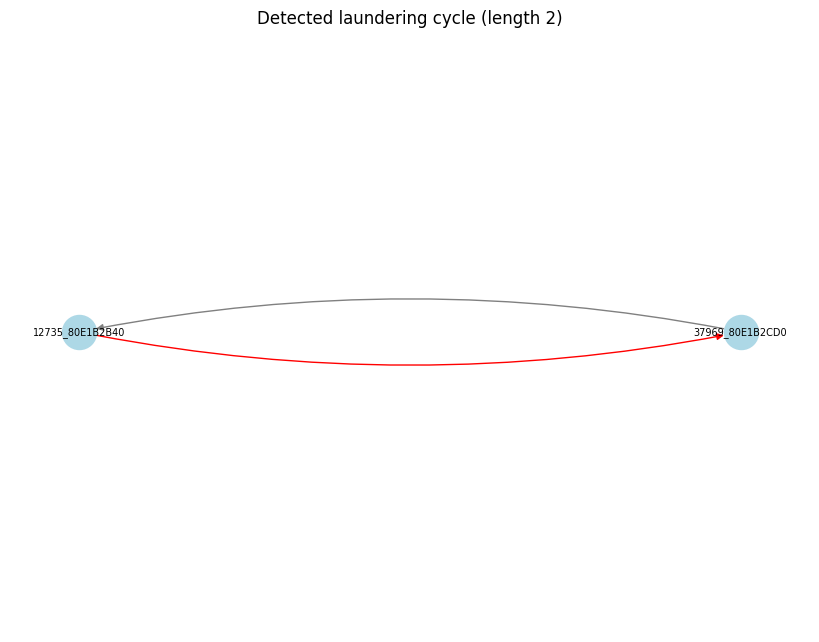

In [ ]:
import matplotlib.pyplot as plt

cycle_to_plot = flagged_cycles[0] if flagged_cycles else cycles[0]
print(f'Plotting cycle of length {len(cycle_to_plot)}: {cycle_to_plot}')

sub = G_sub.subgraph(cycle_to_plot)

plt.figure(figsize=(8, 6))
pos = nx.circular_layout(sub)
edge_colors = ['red' if int(sub[u][v].get('any_laundering', 0)) == 1 else 'gray'
               for u, v in sub.edges()]
nx.draw(sub, pos, node_color='lightblue', node_size=600, with_labels=True,
        font_size=7, edge_color=edge_colors, arrows=True, connectionstyle='arc3,rad=0.1')
plt.title(f'Detected laundering cycle (length {len(cycle_to_plot)})')
plt.savefig(f'{DATA_DIR}/sample_cycle.png', dpi=150, bbox_inches='tight')
plt.show()

864 flagged cycles longer than 2
Plotting cycle of length 6: ['29_80CF37D80', '15231_803A568D0', '1522_8012F9500', '23_8102CA2C0', '9679_8040FAF80', '25960_80AC28E60']


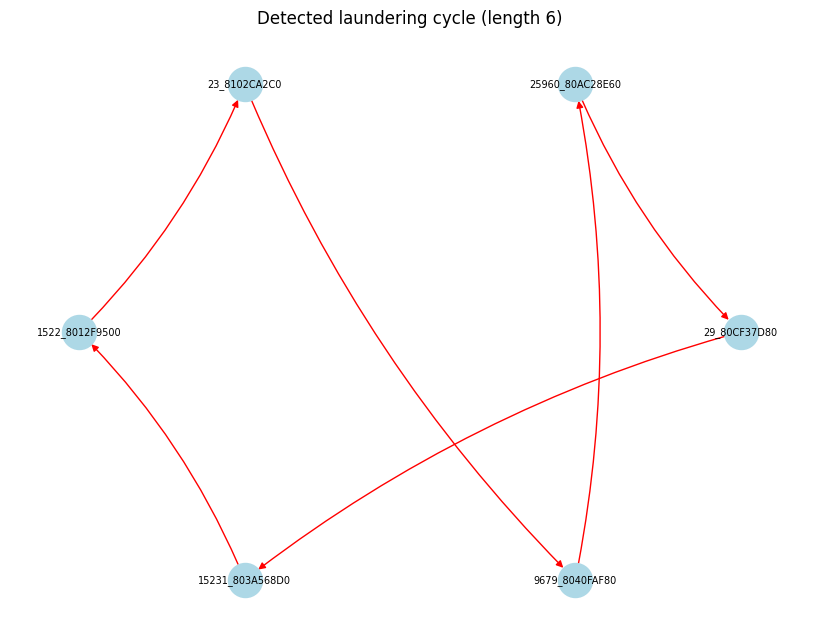

In [ ]:
# Find flagged cycles of length > 2 for a more interesting example
longer_flagged = [c for c in flagged_cycles if len(c) > 2]
print(f'{len(longer_flagged)} flagged cycles longer than 2')

if longer_flagged:
    cycle_to_plot = max(longer_flagged, key=len)  # pick the longest one available
    print(f'Plotting cycle of length {len(cycle_to_plot)}: {cycle_to_plot}')

    sub = G_sub.subgraph(cycle_to_plot)
    plt.figure(figsize=(8, 6))
    pos = nx.circular_layout(sub)
    edge_colors = ['red' if int(sub[u][v].get('any_laundering', 0)) == 1 else 'gray'
                   for u, v in sub.edges()]
    nx.draw(sub, pos, node_color='lightblue', node_size=600, with_labels=True,
            font_size=7, edge_color=edge_colors, arrows=True, connectionstyle='arc3,rad=0.1')
    plt.title(f'Detected laundering cycle (length {len(cycle_to_plot)})')
    plt.savefig(f'{DATA_DIR}/sample_longer_cycle.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('No flagged cycles longer than 2 found — the length-2 example above is your best case')

## 5. Community detection

Groups accounts into clusters of tightly-connected activity using the Louvain method
(fast and standard for graphs this size). We then check whether laundering-flagged edges
are disproportionately concentrated in a small number of communities — if they are, that's
strong evidence graph structure alone carries real signal for detection, which is a
compelling result for your report.


In [ ]:
# networkx's louvain implementation works on undirected graphs
G_undirected = G_clean.to_undirected()

communities = nx.community.louvain_communities(G_undirected, weight='total_amount', seed=42)
print(f'Found {len(communities)} communities')

# Map each node to its community id
node_to_comm = {}
for comm_id, comm_nodes in enumerate(communities):
    for n in comm_nodes:
        node_to_comm[n] = comm_id

comm_sizes = pd.Series([len(c) for c in communities]).describe()
print('\nCommunity size distribution:')
print(comm_sizes)


Found 24811 communities

Community size distribution:
count    24811.000000
mean        17.038169
std        363.686191
min          2.000000
25%          2.000000
50%          2.000000
75%          3.000000
max      40026.000000
dtype: float64


In [ ]:
# For each community, count how many laundering-flagged edges fall inside it
laundering_edges = [(u, v) for u, v, d in G_clean.edges(data=True) if int(d.get('any_laundering', 0)) == 1]

comm_laundering_counts = pd.Series([node_to_comm.get(u) for u, v in laundering_edges]).value_counts()

print('Top 15 communities by number of laundering-flagged edges inside them:')
print(comm_laundering_counts.head(15))
print()
print(f'Total communities containing at least one laundering edge: {(comm_laundering_counts > 0).sum()} / {len(communities)}')


Top 15 communities by number of laundering-flagged edges inside them:
5954     530
4987     439
4914     183
5457     102
14357     93
18849     89
1115      87
11851     87
7601      74
3881      72
3560      64
7536      60
1367      58
13259     52
1557      52
Name: count, dtype: int64

Total communities containing at least one laundering edge: 779 / 24811


In [ ]:
top_community_ids = comm_laundering_counts.head(10).index.tolist()
for cid in top_community_ids:
    size = len(communities[cid])
    print(f'Community {cid}: {size} accounts, {comm_laundering_counts[cid]} laundering edges')

Community 5954: 40026 accounts, 530 laundering edges
Community 4987: 31467 accounts, 439 laundering edges
Community 4914: 5332 accounts, 183 laundering edges
Community 5457: 8579 accounts, 102 laundering edges
Community 14357: 9598 accounts, 93 laundering edges
Community 18849: 11797 accounts, 89 laundering edges
Community 1115: 2294 accounts, 87 laundering edges
Community 11851: 5081 accounts, 87 laundering edges
Community 7601: 8259 accounts, 74 laundering edges
Community 3881: 3528 accounts, 72 laundering edges


Community 1115: 2294 total accounts, 48 laundering edges involving 62 accounts


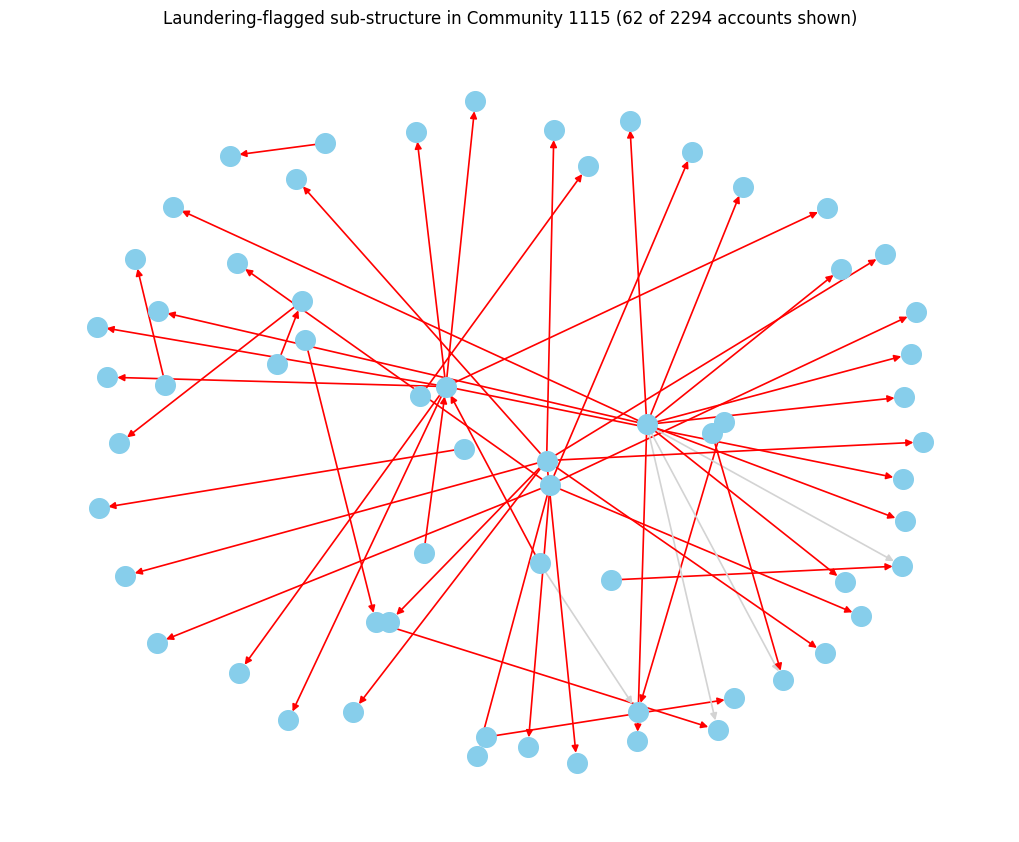

In [ ]:
cid_to_plot = 1115  # smallest of the top 10 — best chance of a readable result

comm_nodes = communities[cid_to_plot]
sub_comm = G_sub.subgraph(comm_nodes)

# Pull only the laundering-flagged edges inside this community, and their directly connected nodes
laundering_edges_in_comm = [(u, v) for u, v, d in sub_comm.edges(data=True)
                             if int(d.get('any_laundering', 0)) == 1]

nodes_to_show = set()
for u, v in laundering_edges_in_comm:
    nodes_to_show.add(u)
    nodes_to_show.add(v)

print(f'Community {cid_to_plot}: {len(comm_nodes)} total accounts, '
      f'{len(laundering_edges_in_comm)} laundering edges involving {len(nodes_to_show)} accounts')

focused_sub = sub_comm.subgraph(nodes_to_show)

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 8))
pos = nx.spring_layout(focused_sub, seed=42, k=0.6)
edge_colors = ['red' if int(focused_sub[u][v].get('any_laundering', 0)) == 1 else 'lightgray'
               for u, v in focused_sub.edges()]
nx.draw(focused_sub, pos, node_color='skyblue', node_size=200,
        with_labels=False, edge_color=edge_colors, arrows=True, width=1.2)
plt.title(f'Laundering-flagged sub-structure in Community {cid_to_plot} '
          f'({len(nodes_to_show)} of {len(comm_nodes)} accounts shown)')
plt.savefig(f'{DATA_DIR}/community_{cid_to_plot}_laundering_focus.png', dpi=150, bbox_inches='tight')
plt.show()

6.Centrality/PageRank Detection

In [ ]:
in_deg = dict(G_sub.in_degree())
out_deg = dict(G_sub.out_degree())

pagerank = nx.pagerank(G_sub, alpha=0.85, weight='total_amount')

centrality_df = pd.DataFrame({
    'node': list(G_sub.nodes()),
    'in_degree': [in_deg[n] for n in G_sub.nodes()],
    'out_degree': [out_deg[n] for n in G_sub.nodes()],
    'pagerank': [pagerank[n] for n in G_sub.nodes()],
})

centrality_df = centrality_df.sort_values('pagerank', ascending=False)
print(centrality_df.head(20))

                   node  in_degree  out_degree  pagerank
15388      70_100428660        545       14230  0.004379
7912       70_1004286A8        328        8846  0.002639
46763      14_8007BC070         79           1  0.001169
38338      14_8007C2A40         77           1  0.001167
22602    5464_8147FC3C0         45           2  0.001042
33468  120193_80C2E7860         69           2  0.001016
18724  232304_80C2D6A60         46           1  0.001010
29443     110_80CFCDFB0         64           1  0.000946
5363   135104_80CFE7120         63           1  0.000944
15269  123102_80DA50520         41           1  0.000924
47973  234347_80DAA12D0         61           1  0.000921
45366  225589_80B51F710         61           1  0.000919
5530   210617_80B533B20         62           1  0.000916
63863  219194_80B13FD20         54           1  0.000813
20673   13029_804CA7210         53           1  0.000811
6580     5627_80B1296D0         54           1  0.000811
35341  212789_804CCCC00        

In [ ]:
# Get the set of account IDs directly involved in laundering-flagged edges
laundering_involved = laundering_nodes  # from earlier — set of accounts in laundering edges

top_20_accounts = set(centrality_df.head(20)['node'])
top_100_accounts = set(centrality_df.head(100)['node'])

overlap_20 = top_20_accounts & laundering_involved
overlap_100 = top_100_accounts & laundering_involved

print(f'Top 20 by PageRank — overlap with laundering-flagged accounts: {len(overlap_20)} / 20')
print(f'Top 100 by PageRank — overlap with laundering-flagged accounts: {len(overlap_100)} / 100')
print(f'Overlapping accounts (top 20): {overlap_20}')

Top 20 by PageRank — overlap with laundering-flagged accounts: 12 / 20
Top 100 by PageRank — overlap with laundering-flagged accounts: 69 / 100
Overlapping accounts (top 20): {'232304_80C2D6A60', '70_1004286A8', '14_8007BC070', '18324_8075F1F70', '110_80CFCDFB0', '120193_80C2E7860', '70_100428660', '5627_80B1296D0', '18067_808F61A50', '13029_804CA7210', '234347_80DAA12D0', '210617_80B533B20'}


In [ ]:
# Which accounts are "high centrality" — top 1% by PageRank within G_sub
top_pagerank_nodes = set(centrality_df.head(int(0.01 * len(centrality_df)))['node'])

# Which accounts sit inside a flagged (laundering-containing) cycle
nodes_in_flagged_cycles = set(n for c in flagged_cycles for n in c)

# Build one row per laundering-flagged edge, checking all three signals
summary_rows = []
for u, v in laundering_edges:
    summary_rows.append({
        'sender': u,
        'receiver': v,
        'sender_top1pct_pagerank': u in top_pagerank_nodes,
        'receiver_top1pct_pagerank': v in top_pagerank_nodes,
        'in_flagged_cycle': u in nodes_in_flagged_cycles or v in nodes_in_flagged_cycles,
        'community_id': node_to_comm.get(u),
    })

summary_df = pd.DataFrame(summary_rows)

pct_high_centrality = (summary_df['sender_top1pct_pagerank'] | summary_df['receiver_top1pct_pagerank']).mean()
pct_in_cycle = summary_df['in_flagged_cycle'].mean()

print(f'Laundering edges involving a top-1%-PageRank account: {pct_high_centrality:.1%}')
print(f'Laundering edges touching a detected short cycle: {pct_in_cycle:.1%}')
print(f'Total laundering edges analyzed: {len(summary_df)}')
print()
print(summary_df.head(10))

Laundering edges involving a top-1%-PageRank account: 37.6%
Laundering edges touching a detected short cycle: 8.9%
Total laundering edges analyzed: 4929

            sender          receiver  sender_top1pct_pagerank  \
0  10057_803DE1580   28628_80ACEE280                    False   
1  28628_80ACEE280    1467_8013C4030                    False   
2  10057_803F405F0    3144_801C3C0D0                    False   
3  10057_803FEFF90       3_802A4BBD0                    False   
4      3_802A4BBD0   24132_803CB3490                    False   
5  10057_80435C9F0   29467_80435CA90                    False   
6     24_80468FA70    1547_8028F2650                    False   
7  28827_805BAB4F0  113744_80B449F70                    False   
8  10057_80C3B78E0    1501_8018C8AF0                    False   
9   1501_8018C8AF0  235920_810FD17D0                    False   

   receiver_top1pct_pagerank  in_flagged_cycle  community_id  
0                      False             False          3560  
1   

**Random Forest ML Risk scoring**

 Step 4: ML Risk Scoring (Random Forest)

Combines the graph signals from Step 3 (PageRank, cycle membership, community info) into a
single feature table at the **account level**, then trains a Random Forest classifier to
produce a 0-1 laundering risk score per account.

**Label definition**: an account is labelled `1` (laundering-involved) if it appears as
sender or receiver on at least one `any_laundering == 1` edge in `G_sub`, else `0`. This
matches how you've been analyzing things all along (account-centric, not per-transaction).

**Class imbalance**: laundering-involved accounts are a small minority (~10% of accounts in
`G_sub`, since it was built around laundering neighborhoods — this ratio would be far lower,
~0.1%, on the full unfiltered graph). We use `class_weight='balanced'` and evaluate with
precision/recall/F1/ROC-AUC — never plain accuracy, which would be misleading here.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import networkx as nx
import pickle

DATA_DIR = '/content/drive/MyDrive/aml_data'

# Re-load the aggregated graph and rebuild G_clean / G_sub exactly as in Step 3,
# in case this is a fresh Colab session with nothing in memory.
G_agg = nx.read_graphml(f'{DATA_DIR}/HI-Small_agg_graph.graphml')

G_clean = G_agg.copy()
G_clean.remove_edges_from(list(nx.selfloop_edges(G_clean)))
G_clean.remove_nodes_from(list(nx.isolates(G_clean)))

laundering_nodes = set()
for u, v, d in G_clean.edges(data=True):
    if int(d.get('any_laundering', 0)) == 1:
        laundering_nodes.add(u)
        laundering_nodes.add(v)

expanded_nodes = set(laundering_nodes)
for n in laundering_nodes:
    expanded_nodes.update(G_clean.predecessors(n))
    expanded_nodes.update(G_clean.successors(n))

G_sub = G_clean.subgraph(expanded_nodes).copy()

print('G_sub — nodes:', G_sub.number_of_nodes(), '| edges:', G_sub.number_of_edges())
print('Laundering-involved accounts:', len(laundering_nodes))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
G_sub — nodes: 64067 | edges: 82238
Laundering-involved accounts: 6357


In [ ]:
# Reload centrality (or recompute if the CSV isn't there)
try:
    centrality_df = pd.read_csv(f'{DATA_DIR}/HI-Small_centrality.csv')
    print('Loaded centrality from CSV:', centrality_df.shape)
except FileNotFoundError:
    print('Centrality CSV not found — recomputing...')
    in_deg = dict(G_sub.in_degree())
    out_deg = dict(G_sub.out_degree())
    pagerank = nx.pagerank(G_sub, alpha=0.85, weight='total_amount')
    centrality_df = pd.DataFrame({
        'node': list(G_sub.nodes()),
        'in_degree': [in_deg[n] for n in G_sub.nodes()],
        'out_degree': [out_deg[n] for n in G_sub.nodes()],
        'pagerank': [pagerank[n] for n in G_sub.nodes()],
    })
    print('Recomputed:', centrality_df.shape)


Centrality CSV not found — recomputing...
Recomputed: (64067, 4)


In [ ]:
import os
# Reload community assignments (or recompute if the pickle isn't there)
try:
    with open(f'{DATA_DIR}/HI-Small_communities.pkl', 'rb') as f:
        comm_data = pickle.load(f)
    communities = comm_data['communities']
    node_to_comm = comm_data['node_to_comm']
    print('Loaded communities from pickle:', len(communities))
except FileNotFoundError:
    print('Communities pickle not found — recomputing (this may take a minute)...')
    G_sub_undirected = G_sub.to_undirected()
    communities = nx.community.louvain_communities(G_sub_undirected, weight='total_amount', seed=42)
    node_to_comm = {}
    for comm_id, comm_nodes in enumerate(communities):
        for n in comm_nodes:
            node_to_comm[n] = comm_id
    print('Recomputed:', len(communities), 'communities')

    # Save the recomputed communities to disk
    comm_data = {'communities': communities, 'node_to_comm': node_to_comm}
    with open(f'{DATA_DIR}/HI-Small_communities.pkl', 'wb') as f:
        pickle.dump(comm_data, f)
    print('Saved recomputed communities to HI-Small_communities.pkl')

Loaded communities from pickle: 1260


In [ ]:
# Recompute short cycles (fast on G_sub — took under a second earlier)
MAX_CYCLE_LEN = 6
cycles = []
for i, cycle in enumerate(nx.simple_cycles(G_sub, length_bound=MAX_CYCLE_LEN)):
    cycles.append(cycle)
    if len(cycles) >= 50000:
        break

def cycle_has_laundering(cycle, G):
    for i in range(len(cycle)):
        u, v = cycle[i], cycle[(i + 1) % len(cycle)]
        if G.has_edge(u, v) and int(G[u][v].get('any_laundering', 0)) == 1:
            return True
    return False

flagged_cycles = [c for c in cycles if cycle_has_laundering(c, G_sub)]
nodes_in_any_cycle = set(n for c in cycles for n in c)
nodes_in_flagged_cycle = set(n for c in flagged_cycles for n in c)

print(f'{len(cycles)} cycles found, {len(flagged_cycles)} flagged')


1606 cycles found, 1079 flagged


## 2. Build the account-level feature table

One row per account in `G_sub`, with:
- **Graph structure**: in-degree, out-degree, PageRank
- **Cycle features**: whether the account sits in any detected cycle, and in a laundering-flagged one specifically
- **Community features**: which community it belongs to, and — importantly — that community's overall laundering rate (this lets the model use "guilt by association" without leaking the individual account's own label)
- **Transaction behavior**: total amount sent/received, transaction counts
- **Label**: 1 if the account appears on any laundering-flagged edge, else 0



In [ ]:
nodes = list(G_sub.nodes())

# --- transaction behavior features, computed directly from the graph edges ---
sent_amount, recv_amount = {}, {}
sent_count, recv_count = {}, {}
for u, v, d in G_sub.edges(data=True):
    sent_amount[u] = sent_amount.get(u, 0) + d.get('total_amount', 0)
    recv_amount[v] = recv_amount.get(v, 0) + d.get('total_amount', 0)
    sent_count[u] = sent_count.get(u, 0) + d.get('n_transactions', 0)
    recv_count[v] = recv_count.get(v, 0) + d.get('n_transactions', 0)

# --- community laundering rate: for each community, what fraction of its EDGES are flagged ---
comm_edge_totals, comm_edge_flagged = {}, {}
for u, v, d in G_sub.edges(data=True):
    cid = node_to_comm.get(u)
    comm_edge_totals[cid] = comm_edge_totals.get(cid, 0) + 1
    if int(d.get('any_laundering', 0)) == 1:
        comm_edge_flagged[cid] = comm_edge_flagged.get(cid, 0) + 1
comm_laundering_rate = {
    cid: comm_edge_flagged.get(cid, 0) / total for cid, total in comm_edge_totals.items()
}

centrality_lookup = centrality_df.set_index('node')

rows = []
for n in nodes:
    cid = node_to_comm.get(n)
    rows.append({
        'node': n,
        'in_degree': G_sub.in_degree(n),
        'out_degree': G_sub.out_degree(n),
        'pagerank': centrality_lookup.loc[n, 'pagerank'] if n in centrality_lookup.index else 0,
        'total_sent': sent_amount.get(n, 0),
        'total_received': recv_amount.get(n, 0),
        'n_sent_txns': sent_count.get(n, 0),
        'n_received_txns': recv_count.get(n, 0),
        'in_any_cycle': int(n in nodes_in_any_cycle),
        'in_flagged_cycle': int(n in nodes_in_flagged_cycle),
        'community_id': cid,
        'community_laundering_rate': comm_laundering_rate.get(cid, 0),
        'community_size': len(communities[cid]) if cid is not None else 0,
        'label': int(n in laundering_nodes),
    })

feature_df = pd.DataFrame(rows)
print('Feature table shape:', feature_df.shape)
print('\nLabel distribution:')
print(feature_df['label'].value_counts())
print(f"Positive rate: {feature_df['label'].mean():.2%}")
feature_df.head()


Feature table shape: (64067, 14)

Label distribution:
label
0    57710
1     6357
Name: count, dtype: int64
Positive rate: 9.92%


,node,in_degree,out_degree,pagerank,total_sent,total_received,n_sent_txns,n_received_txns,in_any_cycle,in_flagged_cycle,community_id,community_laundering_rate,community_size,label
0,23_800164D30,1,1,0.000009,25002.10,6490.84,10,1,0,0,63,0.098361,110,1
1,1299_800FA2AA0,1,0,0.000009,0.00,4448.26,0,2,0,0,264,0.028919,10343,0
2,25309_80E275A00,1,0,0.000022,0.00,3217911.06,0,2,0,0,410,0.065789,91,0
3,3_805CB52D0,0,4,0.000009,10370.49,0.00,5,0,0,0,890,0.018939,1432,0
4,11657_800FD6B00,2,4,0.000009,12923614.96,664389.54,73,11,0,0,778,0.089286,41,1


## 3. Train / test split and model training

Stratified split to preserve the label ratio in both sets. `class_weight='balanced'` tells
the Random Forest to weight the minority (laundering) class more heavily during training,
since otherwise it would just learn to predict "not laundering" for everything.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, precision_recall_curve, RocCurveDisplay)
import matplotlib.pyplot as plt

feature_cols = ['in_degree', 'out_degree', 'pagerank', 'total_sent', 'total_received',
                 'n_sent_txns', 'n_received_txns', 'in_any_cycle', 'in_flagged_cycle',
                 'community_laundering_rate', 'community_size']

X = feature_df[feature_cols]
y = feature_df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print('Train:', X_train.shape, '| positive rate:', y_train.mean())
print('Test :', X_test.shape, '| positive rate:', y_test.mean())

clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
clf.fit(X_train, y_train)
print('Model trained.')


Train: (51253, 11) | positive rate: 0.09923321561664683
Test : (12814, 11) | positive rate: 0.09918838770095208
Model trained.


## 4. Evaluate — precision, recall, F1, ROC-AUC

This is the section to screenshot directly for your Phase 3 slides. Plain accuracy is not
reported on its own because with any class imbalance it can look artificially high while
missing most of the actual laundering accounts — precision/recall/F1 tell the real story.


In [ ]:
y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=['Not Laundering', 'Laundering']))
print(f'ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}')

cm = confusion_matrix(y_test, y_pred)
print('\nConfusion matrix:')
print(f'                  Predicted: Not Laundering | Predicted: Laundering')
print(f'Actual: Not Laundering    {cm[0][0]:>8}          |  {cm[0][1]:>8}')
print(f'Actual: Laundering        {cm[1][0]:>8}          |  {cm[1][1]:>8}')


                precision    recall  f1-score   support

Not Laundering       0.98      0.95      0.97     11543
    Laundering       0.66      0.82      0.73      1271

      accuracy                           0.94     12814
     macro avg       0.82      0.89      0.85     12814
  weighted avg       0.95      0.94      0.94     12814

ROC-AUC: 0.9648

Confusion matrix:
                  Predicted: Not Laundering | Predicted: Laundering
Actual: Not Laundering       11001          |       542
Actual: Laundering             228          |      1043


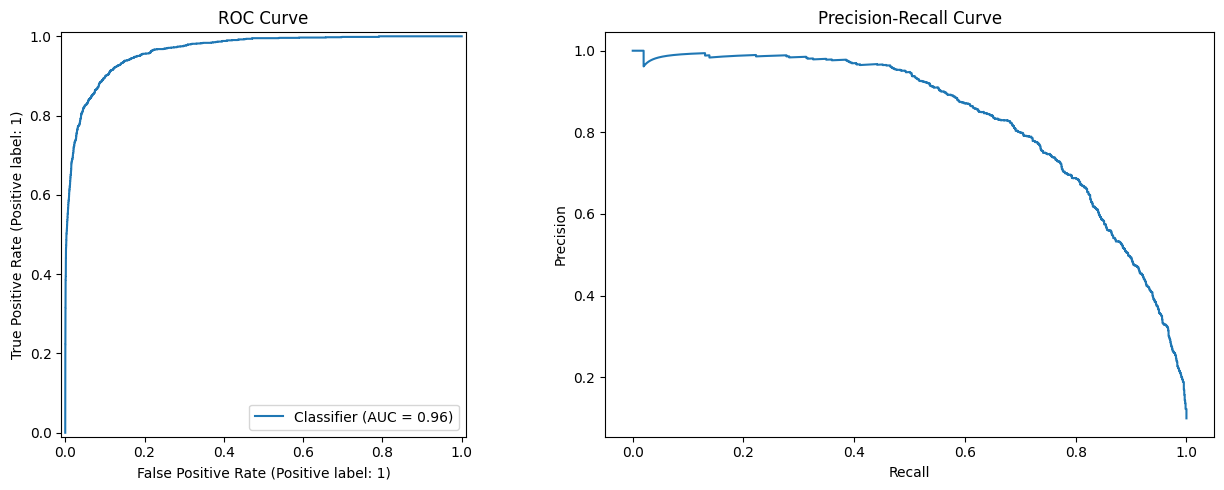

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[0])
axes[0].set_title('ROC Curve')

precision, recall, _ = precision_recall_curve(y_test, y_proba)
axes[1].plot(recall, precision)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve')

plt.tight_layout()
plt.savefig(f'{DATA_DIR}/step4_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Feature importance

Shows which graph signals the model actually relied on most — useful for your report to
explain *why* the model works, not just that it works. Expect `community_laundering_rate`
and `pagerank` to rank highly, consistent with what Step 3 already showed manually.


pagerank                     0.272811
in_degree                    0.146837
total_sent                   0.136979
n_sent_txns                  0.097392
out_degree                   0.086725
community_laundering_rate    0.079890
n_received_txns              0.060756
total_received               0.057632
community_size               0.054702
in_any_cycle                 0.004124
in_flagged_cycle             0.002152
dtype: float64


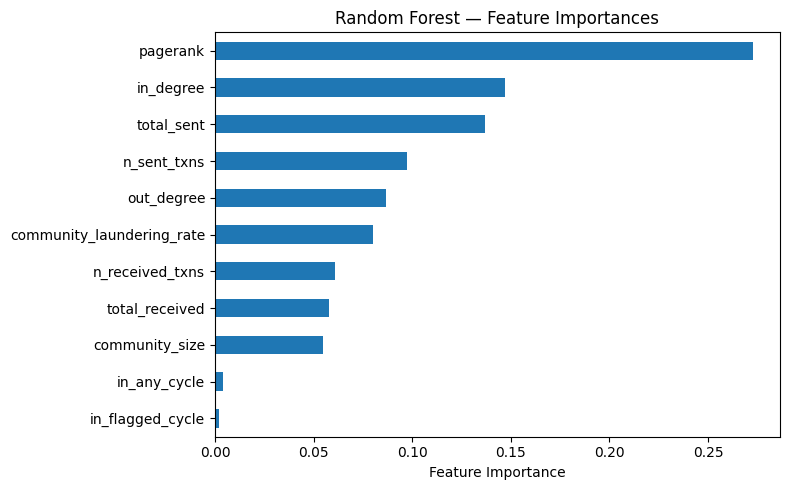

In [ ]:
importances = pd.Series(clf.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(importances)

plt.figure(figsize=(8, 5))
importances.plot(kind='barh')
plt.gca().invert_yaxis()
plt.xlabel('Feature Importance')
plt.title('Random Forest — Feature Importances')
plt.tight_layout()
plt.savefig(f'{DATA_DIR}/step4_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Produce a 0-1 risk score for every account and save

Applies the trained model to the full feature table (not just the test set) to produce a
final risk score per account — this is the artifact your dashboard (Phase 3) will visualize.


In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
import pickle
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

DATA_DIR = '/content/drive/MyDrive/aml_data'

# --- Re-establish graph and analytical data needed for feature_df ---
# These steps ensure feature_df is constructed correctly with all expected columns.

# Re-load the aggregated graph and rebuild G_clean / G_sub exactly as in Step 3
G_agg = nx.read_graphml(f'{DATA_DIR}/HI-Small_agg_graph.graphml')

G_clean = G_agg.copy()
G_clean.remove_edges_from(list(nx.selfloop_edges(G_clean)))
G_clean.remove_nodes_from(list(nx.isolates(G_clean)))

laundering_nodes = set()
for u, v, d in G_clean.edges(data=True):
    if int(d.get('any_laundering', 0)) == 1:
        laundering_nodes.add(u)
        laundering_nodes.add(v)

expanded_nodes = set(laundering_nodes)
for n in laundering_nodes:
    expanded_nodes.update(G_clean.predecessors(n))
    expanded_nodes.update(G_clean.successors(n))

G_sub = G_clean.subgraph(expanded_nodes).copy()

# Reload centrality (or recompute if the CSV isn't there)
try:
    centrality_df = pd.read_csv(f'{DATA_DIR}/HI-Small_centrality.csv')
except FileNotFoundError:
    in_deg = dict(G_sub.in_degree())
    out_deg = dict(G_sub.out_degree())
    pagerank = nx.pagerank(G_sub, alpha=0.85, weight='total_amount')
    centrality_df = pd.DataFrame({
        'node': list(G_sub.nodes()),
        'in_degree': [in_deg[n] for n in G_sub.nodes()],
        'out_degree': [out_deg[n] for n in G_sub.nodes()],
        'pagerank': [pagerank[n] for n in G_sub.nodes()],
    })

# Reload community assignments (or recompute if the pickle isn't there)
try:
    with open(f'{DATA_DIR}/HI-Small_communities.pkl', 'rb') as f:
        comm_data = pickle.load(f)
    communities = comm_data['communities']
    node_to_comm = comm_data['node_to_comm']
except FileNotFoundError:
    G_sub_undirected = G_sub.to_undirected()
    communities = nx.community.louvain_communities(G_sub_undirected, weight='total_amount', seed=42)
    node_to_comm = {}
    for comm_id, comm_nodes in enumerate(communities):
        for n in comm_nodes:
            node_to_comm[n] = comm_id

# Recompute short cycles
MAX_CYCLE_LEN = 6
cycles = []
for i, cycle in enumerate(nx.simple_cycles(G_sub, length_bound=MAX_CYCLE_LEN)):
    cycles.append(cycle)
    if len(cycles) >= 50000:
        break

def cycle_has_laundering(cycle, G):
    for i in range(len(cycle)):
        u, v = cycle[i], cycle[(i + 1) % len(cycle)]
        if G.has_edge(u, v) and int(G[u][v].get('any_laundering', 0)) == 1:
            return True
    return False

flagged_cycles = [c for c in cycles if cycle_has_laundering(c, G_sub)]
nodes_in_any_cycle = set(n for c in cycles for n in c)
nodes_in_flagged_cycle = set(n for c in flagged_cycles for n in c)

# --- Rebuild feature_df ---
nodes = list(G_sub.nodes())

sent_amount, recv_amount = {}, {}
sent_count, recv_count = {}, {}
for u, v, d in G_sub.edges(data=True):
    sent_amount[u] = sent_amount.get(u, 0) + d.get('total_amount', 0)
    recv_amount[v] = recv_amount.get(v, 0) + d.get('total_amount', 0)
    sent_count[u] = sent_count.get(u, 0) + d.get('n_transactions', 0)
    recv_count[v] = recv_count.get(v, 0) + d.get('n_transactions', 0)

comm_edge_totals, comm_edge_flagged = {}, {}
for u, v, d in G_sub.edges(data=True):
    cid = node_to_comm.get(u)
    comm_edge_totals[cid] = comm_edge_totals.get(cid, 0) + 1
    if int(d.get('any_laundering', 0)) == 1:
        comm_edge_flagged[cid] = comm_edge_flagged.get(cid, 0) + 1
comm_laundering_rate = {
    cid: comm_edge_flagged.get(cid, 0) / total for cid, total in comm_edge_totals.items()
}

centrality_lookup = centrality_df.set_index('node')

rows = []
for n in nodes:
    cid = node_to_comm.get(n)
    rows.append({
        'node': n,
        'in_degree': G_sub.in_degree(n),
        'out_degree': G_sub.out_degree(n),
        'pagerank': centrality_lookup.loc[n, 'pagerank'] if n in centrality_lookup.index else 0,
        'total_sent': sent_amount.get(n, 0),
        'total_received': recv_amount.get(n, 0),
        'n_sent_txns': sent_count.get(n, 0),
        'n_received_txns': recv_count.get(n, 0),
        'in_any_cycle': int(n in nodes_in_any_cycle),
        'in_flagged_cycle': int(n in nodes_in_flagged_cycle),
        'community_id': cid,
        'community_laundering_rate': comm_laundering_rate.get(cid, 0),
        'community_size': len(communities[cid]) if cid is not None else 0,
        'label': int(n in laundering_nodes),
    })

feature_df = pd.DataFrame(rows)

# --- Original code to apply the model ---
# Redefine feature_cols as it was for the original clf model
feature_cols = ['in_degree', 'out_degree', 'pagerank', 'total_sent', 'total_received',
                 'n_sent_txns', 'n_received_txns', 'in_any_cycle', 'in_flagged_cycle',
                 'community_laundering_rate', 'community_size']

# Recreate X and y based on the feature_df in memory
X = feature_df[feature_cols]
y = feature_df['label']

# Re-split data to get X_train and y_train for fitting clf
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Re-instantiate and re-train the RandomForestClassifier
clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
clf.fit(X_train, y_train)

feature_df['risk_score'] = clf.predict_proba(X)[:, 1]

risk_output = feature_df[['node', 'risk_score', 'label', 'in_degree', 'out_degree',
                            'pagerank', 'community_id']].sort_values('risk_score', ascending=False)

print('Top 15 highest-risk accounts:')
print(risk_output.head(15))

risk_output.to_csv(f'{DATA_DIR}/HI-Small_risk_scores.csv', index=False)

joblib.dump(clf, f'{DATA_DIR}/HI-Small_rf_model.pkl')

print('\nSaved risk scores and trained model to Drive.')

Top 15 highest-risk accounts:
                  node  risk_score  label  in_degree  out_degree  pagerank  \
47522  16224_8052D0490    0.999341      1          4           5  0.000067   
14055  15231_803A568D0    0.999286      1          3           6  0.000032   
35677   1467_8003E2010    0.999267      1          4           8  0.000032   
21272   1601_80033AD80    0.999261      1          5           9  0.000034   
63833   1674_8003E5BD0    0.999248      1          5           9  0.000035   
27421   3149_8032FADC0    0.999241      1          6           6  0.000035   
47039   1490_80056CE80    0.999204      1          5          11  0.000032   
44965    795_8007EC4D0    0.999174      1          5           7  0.000052   
20023   1655_8010D1180    0.999083      1          4           7  0.000039   
16626    119_80FD88340    0.999073      1          4           7  0.000039   
52524  16649_80614A030    0.999068      1          7           6  0.000043   
33540  21831_800D50B30    0.999046

**Unsupervised Testing Using Isolation Forest**

# AML Graph Project — Unsupervised Anomaly Detection (Isolation Forest)

Step 4's Random Forest was **supervised** — it learned directly from the `Is_Laundering`
label. This notebook flips that: **Isolation Forest never sees the label during training**
at all. It just looks at each account's graph features and asks "how different is this
account from the general population?" — accounts that are easy to isolate (few similar
accounts nearby in feature space) get flagged as anomalies.

This matters for your report because **most real-world AML systems don't have clean labels**
— banks often don't know in advance which accounts are laundering. An unsupervised method
that still finds real laundering accounts, purely from structural weirdness, is a much
stronger and more realistic claim than a supervised model that had the answer key.

We'll then check — only *after* training, purely for evaluation — how well the anomalies it
found line up with the real labels, and compare against Step 4's supervised results.


In [ ]:
## 1. Reload the same feature table built in Step 4

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import networkx as nx
import pickle

DATA_DIR = '/content/drive/MyDrive/aml_data'

# Reuse the saved risk-score table from Step 4 — it already has the graph features
# (in/out degree, pagerank, community info) joined with the true label for evaluation later.
risk_df = pd.read_csv(f'{DATA_DIR}/HI-Small_risk_scores.csv')
print('Loaded:', risk_df.shape)
risk_df.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded: (64067, 7)


,node,risk_score,label,in_degree,out_degree,pagerank,community_id
0,16224_8052D0490,0.999341,1,4,5,0.000067,56
1,15231_803A568D0,0.999286,1,3,6,0.000032,283
2,1467_8003E2010,0.999267,1,4,8,0.000032,899
3,1601_80033AD80,0.999261,1,5,9,0.000034,803
4,1674_8003E5BD0,0.999248,1,5,9,0.000035,171


In [ ]:
# The saved risk-score CSV only kept a subset of columns — rebuild the full feature table
# the same way Step 4 did, so Isolation Forest has the same feature richness to work with.
G_agg = nx.read_graphml(f'{DATA_DIR}/HI-Small_agg_graph.graphml')
G_clean = G_agg.copy()
G_clean.remove_edges_from(list(nx.selfloop_edges(G_clean)))
G_clean.remove_nodes_from(list(nx.isolates(G_clean)))

laundering_nodes = set()
for u, v, d in G_clean.edges(data=True):
    if int(d.get('any_laundering', 0)) == 1:
        laundering_nodes.add(u)
        laundering_nodes.add(v)

expanded_nodes = set(laundering_nodes)
for n in laundering_nodes:
    expanded_nodes.update(G_clean.predecessors(n))
    expanded_nodes.update(G_clean.successors(n))

G_sub = G_clean.subgraph(expanded_nodes).copy()

with open(f'{DATA_DIR}/HI-Small_communities.pkl', 'rb') as f:
    comm_data = pickle.load(f)
communities = comm_data['communities']
node_to_comm = comm_data['node_to_comm']

sent_amount, recv_amount = {}, {}
sent_count, recv_count = {}, {}
for u, v, d in G_sub.edges(data=True):
    sent_amount[u] = sent_amount.get(u, 0) + d.get('total_amount', 0)
    recv_amount[v] = recv_amount.get(v, 0) + d.get('total_amount', 0)
    sent_count[u] = sent_count.get(u, 0) + d.get('n_transactions', 0)
    recv_count[v] = recv_count.get(v, 0) + d.get('n_transactions', 0)

comm_edge_totals, comm_edge_flagged = {}, {}
for u, v, d in G_sub.edges(data=True):
    cid = node_to_comm.get(u)
    comm_edge_totals[cid] = comm_edge_totals.get(cid, 0) + 1
    if int(d.get('any_laundering', 0)) == 1:
        comm_edge_flagged[cid] = comm_edge_flagged.get(cid, 0) + 1
comm_laundering_rate = {cid: comm_edge_flagged.get(cid, 0) / t for cid, t in comm_edge_totals.items()}

rows = []
for n in G_sub.nodes():
    cid = node_to_comm.get(n)
    rows.append({
        'node': n,
        'in_degree': G_sub.in_degree(n),
        'out_degree': G_sub.out_degree(n),
        'total_sent': sent_amount.get(n, 0),
        'total_received': recv_amount.get(n, 0),
        'n_sent_txns': sent_count.get(n, 0),
        'n_received_txns': recv_count.get(n, 0),
        'community_size': len(communities[cid]) if cid is not None else 0,
        'community_laundering_rate': comm_laundering_rate.get(cid, 0),
        'label': int(n in laundering_nodes),
    })

feature_df = pd.DataFrame(rows).merge(
    risk_df[['node', 'pagerank']], on='node', how='left'
)
print('Feature table:', feature_df.shape)
feature_df.head()


Feature table: (64067, 11)


,node,in_degree,out_degree,total_sent,total_received,n_sent_txns,n_received_txns,community_size,community_laundering_rate,label,pagerank
0,23_800164D30,1,1,25002.10,6490.84,10,1,110,0.098361,1,0.000009
1,1299_800FA2AA0,1,0,0.00,4448.26,0,2,10343,0.028919,0,0.000009
2,25309_80E275A00,1,0,0.00,3217911.06,0,2,91,0.065789,0,0.000022
3,3_805CB52D0,0,4,10370.49,0.00,5,0,1432,0.018939,0,0.000009
4,11657_800FD6B00,2,4,12923614.96,664389.54,73,11,41,0.089286,1,0.000009


## 2. Train Isolation Forest — WITHOUT the label

`contamination` is set to roughly match the true positive rate in this subgraph (~10%),
which tells the model what fraction of accounts to expect as anomalies. In a real
deployment you wouldn't know this exactly and would tune it — we're using the known rate
here since it's a reasonable estimate and keeps the comparison against Step 4 fair. Note:
`community_laundering_rate` is deliberately **excluded** here, since it was derived using
the label — including it would make this not-truly-unsupervised.


In [ ]:
from sklearn.ensemble import IsolationForest

# Only structural/behavioral features — nothing derived from the label
unsupervised_features = ['in_degree', 'out_degree', 'pagerank', 'total_sent',
                          'total_received', 'n_sent_txns', 'n_received_txns', 'community_size']

X_unsup = feature_df[unsupervised_features].fillna(0)

true_positive_rate = feature_df['label'].mean()
print(f'True positive rate (used to set contamination): {true_positive_rate:.4f}')

iso_forest = IsolationForest(
    n_estimators=300,
    contamination=true_positive_rate,
    random_state=42,
    n_jobs=-1
)
iso_forest.fit(X_unsup)

# decision_function: higher = more normal, lower/negative = more anomalous.
# We flip the sign so higher = more anomalous, matching intuition for a "risk score".
feature_df['anomaly_score'] = -iso_forest.decision_function(X_unsup)
feature_df['is_anomaly'] = (iso_forest.predict(X_unsup) == -1).astype(int)

print(f"Flagged as anomalies: {feature_df['is_anomaly'].sum()} / {len(feature_df)}")


True positive rate (used to set contamination): 0.0992
Flagged as anomalies: 6357 / 64067


## 3. Evaluate against the real labels (evaluation only — not used in training)

This is the key check: the model never saw `label` during training. Now we see how well
its anomaly flags line up with reality.


In [ ]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

print(classification_report(feature_df['label'], feature_df['is_anomaly'],
                             target_names=['Not Laundering', 'Laundering']))
print(f"ROC-AUC (using continuous anomaly_score): {roc_auc_score(feature_df['label'], feature_df['anomaly_score']):.4f}")

cm = confusion_matrix(feature_df['label'], feature_df['is_anomaly'])
print('\nConfusion matrix:')
print(f'                  Predicted: Not Anomaly | Predicted: Anomaly')
print(f'Actual: Not Laundering    {cm[0][0]:>8}        |  {cm[0][1]:>8}')
print(f'Actual: Laundering        {cm[1][0]:>8}        |  {cm[1][1]:>8}')


                precision    recall  f1-score   support

Not Laundering       0.94      0.94      0.94     57710
    Laundering       0.43      0.43      0.43      6357

      accuracy                           0.89     64067
     macro avg       0.68      0.68      0.68     64067
  weighted avg       0.89      0.89      0.89     64067

ROC-AUC (using continuous anomaly_score): 0.8146

Confusion matrix:
                  Predicted: Not Anomaly | Predicted: Anomaly
Actual: Not Laundering       54092        |      3618
Actual: Laundering            3618        |      2739


## 4. Compare against Step 4's supervised Random Forest

Puts the two approaches side by side — this comparison table is exactly what belongs in
your report/slide: supervised vs. unsupervised trade-off.


                         Method Uses labels during training  ROC-AUC
     Random Forest (supervised)                         Yes 0.959700
Isolation Forest (unsupervised)                          No 0.814618


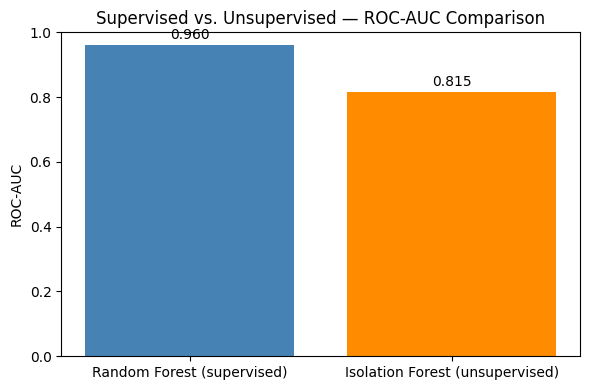

In [ ]:
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    'Method': ['Random Forest (supervised)', 'Isolation Forest (unsupervised)'],
    'Uses labels during training': ['Yes', 'No'],
    'ROC-AUC': [0.9597, roc_auc_score(feature_df['label'], feature_df['anomaly_score'])],
})
print(comparison.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(comparison['Method'], comparison['ROC-AUC'], color=['steelblue', 'darkorange'])
ax.set_ylim(0, 1)
ax.set_ylabel('ROC-AUC')
ax.set_title('Supervised vs. Unsupervised — ROC-AUC Comparison')
for i, v in enumerate(comparison['ROC-AUC']):
    ax.text(i, v + 0.02, f'{v:.3f}', ha='center')
plt.tight_layout()
plt.savefig(f'{DATA_DIR}/iso_forest_vs_rf_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Where do the two methods agree / disagree?

Accounts flagged by *both* methods are your highest-confidence alerts — worth calling out
specifically as "cross-validated" suspicious accounts in your report, since two independent
approaches (one that saw labels, one that didn't) agreeing is strong evidence.


In [ ]:
rf_risk = risk_df.set_index('node')['risk_score']
feature_df['rf_risk_score'] = feature_df['node'].map(rf_risk)
feature_df['rf_flagged'] = feature_df['rf_risk_score'] > 0.5

both_flagged = feature_df[(feature_df['is_anomaly'] == 1) & (feature_df['rf_flagged'])]
only_iso = feature_df[(feature_df['is_anomaly'] == 1) & (~feature_df['rf_flagged'])]
only_rf = feature_df[(feature_df['is_anomaly'] == 0) & (feature_df['rf_flagged'])]

print(f'Flagged by BOTH methods: {len(both_flagged)} accounts '
      f'({(both_flagged["label"] == 1).mean():.1%} are true laundering accounts)')
print(f'Flagged ONLY by Isolation Forest: {len(only_iso)} accounts '
      f'({(only_iso["label"] == 1).mean():.1%} are true laundering accounts)')
print(f'Flagged ONLY by Random Forest: {len(only_rf)} accounts '
      f'({(only_rf["label"] == 1).mean():.1%} are true laundering accounts)')

both_flagged.sort_values('anomaly_score', ascending=False).head(10)[
    ['node', 'anomaly_score', 'rf_risk_score', 'label']
]


Flagged by BOTH methods: 3325 accounts (80.8% are true laundering accounts)
Flagged ONLY by Isolation Forest: 3032 accounts (1.7% are true laundering accounts)
Flagged ONLY by Random Forest: 4568 accounts (66.0% are true laundering accounts)


,node,anomaly_score,rf_risk_score,label
15388,70_100428660,0.367632,0.990043,1
53927,70_100428780,0.364012,0.979476,1
47678,70_1004287C8,0.362682,0.965683,1
4157,70_100428738,0.362302,0.993165,1
7912,70_1004286A8,0.361923,0.995027,1
7230,70_1004286F0,0.360029,0.998434,1
30662,70_1004289C0,0.360029,0.997026,1
3258,70_100428978,0.359272,0.998422,1
33843,70_100428810,0.358894,0.991643,1
4969,70_1004288A0,0.353995,0.995197,1


In [ ]:
feature_df[['node', 'anomaly_score', 'is_anomaly', 'rf_risk_score', 'rf_flagged', 'label']].to_csv(
    f'{DATA_DIR}/HI-Small_isolation_forest_results.csv', index=False
)
print('Saved Isolation Forest results to Drive.')


Saved Isolation Forest results to Drive.


# AML Graph Project — Full-Graph Validation

Every result so far (Step 4's Random Forest, the Isolation Forest) was trained and
evaluated on `G_sub` — the ~64,067-account neighborhood built around known laundering
activity, where laundering accounts are ~10% of the population. That subgraph was built
*around* laundering accounts, so finding laundering accounts to be structurally central
within it is partly expected by construction.

This notebook re-tests the trained models on a **random sample from the full 515,088-node
graph**, where the true laundering rate is much lower (~1%, since some laundering-involved
accounts sit outside `G_sub`'s immediate neighborhood too — computed below). This is the
honest, harder test: if the models still perform well here, that's real evidence the
approach generalizes, not just an artifact of how the evaluation subgraph was built.


## 1. Load the full graph and the trained models

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import networkx as nx
import pickle
import joblib

DATA_DIR = '/content/drive/MyDrive/aml_data'

G_agg = nx.read_graphml(f'{DATA_DIR}/HI-Small_agg_graph.graphml')
G_full_clean = G_agg.copy()
G_full_clean.remove_edges_from(list(nx.selfloop_edges(G_full_clean)))
G_full_clean.remove_nodes_from(list(nx.isolates(G_full_clean)))

print('Full clean graph — nodes:', G_full_clean.number_of_nodes(),
      '| edges:', G_full_clean.number_of_edges())

rf_model = joblib.load(f'{DATA_DIR}/HI-Small_rf_model.pkl')
print('Loaded trained Random Forest model.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Full clean graph — nodes: 422734 | edges: 647939
Loaded trained Random Forest model.


## 2. Compute the true laundering rate across the FULL graph

This is the honest baseline number — how rare laundering actually is once you're not
looking only at the neighborhood built around it.


In [ ]:
all_laundering_nodes = set()
for u, v, d in G_full_clean.edges(data=True):
    if int(d.get('any_laundering', 0)) == 1:
        all_laundering_nodes.add(u)
        all_laundering_nodes.add(v)

true_full_rate = len(all_laundering_nodes) / G_full_clean.number_of_nodes()
print(f'Laundering-involved accounts in the FULL graph: {len(all_laundering_nodes)} '
      f'({true_full_rate:.3%} of {G_full_clean.number_of_nodes()} accounts)')


Laundering-involved accounts in the FULL graph: 6357 (1.504% of 422734 accounts)


## 3. Build a random sample from the full graph

Takes a random sample of accounts from the entire graph (not restricted to any laundering
neighborhood), sized to keep computation manageable, then computes the same features used
to train the model — degree, PageRank, community info — **from scratch on this sample's
local context**, exactly as a real deployment would for an arbitrary, unseen account.


In [ ]:
SAMPLE_SIZE = 60000  # comparable size to G_sub, for a fair comparison

np.random.seed(42)
all_nodes = list(G_full_clean.nodes())

# Guarantee every laundering account is included (so we can actually measure recall),
# plus a random sample of the rest to fill out the population at the true ~0.1%-ish rate
non_laundering_nodes = [n for n in all_nodes if n not in all_laundering_nodes]
n_non_laundering_to_sample = SAMPLE_SIZE - len(all_laundering_nodes)
sampled_non_laundering = np.random.choice(non_laundering_nodes,
                                           size=n_non_laundering_to_sample, replace=False)

sample_nodes = set(all_laundering_nodes) | set(sampled_non_laundering)
print(f'Validation sample: {len(sample_nodes)} accounts '
      f'({len(all_laundering_nodes)} laundering, {n_non_laundering_to_sample} legitimate)')
print(f'True laundering rate in this sample: {len(all_laundering_nodes)/len(sample_nodes):.3%}')


Validation sample: 60000 accounts (6357 laundering, 53643 legitimate)
True laundering rate in this sample: 10.595%


## 4. Compute features for the sample using the FULL graph's structure

Important: degree and PageRank are computed using each account's position in the **entire**
515K-node graph, not a laundering-focused subgraph — this is the fair, unbiased version of
the features.


In [ ]:
# PageRank on the full graph — heavier than on G_sub, but should still finish in a
# few minutes since it's one pass over ~1M edges
print('Computing PageRank on the full graph — this may take a few minutes...')
full_pagerank = nx.pagerank(G_full_clean, alpha=0.85, weight='total_amount')
print('Done.')


Computing PageRank on the full graph — this may take a few minutes...
Done.


In [ ]:
sent_amount, recv_amount = {}, {}
sent_count, recv_count = {}, {}
for u, v, d in G_full_clean.edges(data=True):
    sent_amount[u] = sent_amount.get(u, 0) + d.get('total_amount', 0)
    recv_amount[v] = recv_amount.get(v, 0) + d.get('total_amount', 0)
    sent_count[u] = sent_count.get(u, 0) + d.get('n_transactions', 0)
    recv_count[v] = recv_count.get(v, 0) + d.get('n_transactions', 0)

# Community detection on the full graph (Louvain) — needed for community_laundering_rate
print('Running community detection on the full graph...')
G_full_undirected = G_full_clean.to_undirected()
full_communities = nx.community.louvain_communities(G_full_undirected, weight='total_amount', seed=42)
full_node_to_comm = {}
for cid, nodes in enumerate(full_communities):
    for n in nodes:
        full_node_to_comm[n] = cid
print(f'Found {len(full_communities)} communities in the full graph.')

comm_edge_totals, comm_edge_flagged = {}, {}
for u, v, d in G_full_clean.edges(data=True):
    cid = full_node_to_comm.get(u)
    comm_edge_totals[cid] = comm_edge_totals.get(cid, 0) + 1
    if int(d.get('any_laundering', 0)) == 1:
        comm_edge_flagged[cid] = comm_edge_flagged.get(cid, 0) + 1
full_comm_laundering_rate = {cid: comm_edge_flagged.get(cid, 0) / t for cid, t in comm_edge_totals.items()}


Running community detection on the full graph...
Found 24811 communities in the full graph.


In [ ]:
rows = []
for n in sample_nodes:
    cid = full_node_to_comm.get(n)
    rows.append({
        'node': n,
        'in_degree': G_full_clean.in_degree(n),
        'out_degree': G_full_clean.out_degree(n),
        'pagerank': full_pagerank.get(n, 0),
        'total_sent': sent_amount.get(n, 0),
        'total_received': recv_amount.get(n, 0),
        'n_sent_txns': sent_count.get(n, 0),
        'n_received_txns': recv_count.get(n, 0),
        'in_any_cycle': 0,        # cycle search on the full graph is impractical — omitted here
        'in_flagged_cycle': 0,    # (Step 4's feature importance showed this mattered least anyway)
        'community_laundering_rate': full_comm_laundering_rate.get(cid, 0),
        'community_size': len(full_communities[cid]) if cid is not None else 0,
        'label': int(n in all_laundering_nodes),
    })

full_validation_df = pd.DataFrame(rows)
print('Full-graph validation feature table:', full_validation_df.shape)
print(full_validation_df['label'].value_counts())


Full-graph validation feature table: (60000, 13)
label
0    53643
1     6357
Name: count, dtype: int64


## 5. Run the ALREADY-TRAINED Random Forest on this fresh, unbiased sample

Important: we are not retraining — this is the exact model trained in Step 4, now applied
to accounts and features it was never fit on. This is the real generalization test.


In [ ]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

feature_cols = ['in_degree', 'out_degree', 'pagerank', 'total_sent', 'total_received',
                 'n_sent_txns', 'n_received_txns', 'in_any_cycle', 'in_flagged_cycle',
                 'community_laundering_rate', 'community_size']

X_full = full_validation_df[feature_cols]
y_full = full_validation_df['label']

y_full_pred = rf_model.predict(X_full)
y_full_proba = rf_model.predict_proba(X_full)[:, 1]

print('=== Full-graph validation (model trained on G_sub, tested on the full graph) ===\n')
print(classification_report(y_full, y_full_pred, target_names=['Not Laundering', 'Laundering']))
print(f'ROC-AUC: {roc_auc_score(y_full, y_full_proba):.4f}')

cm = confusion_matrix(y_full, y_full_pred)
print('\nConfusion matrix:')
print(f'                  Predicted: Not Laundering | Predicted: Laundering')
print(f'Actual: Not Laundering    {cm[0][0]:>8}          |  {cm[0][1]:>8}')
print(f'Actual: Laundering        {cm[1][0]:>8}          |  {cm[1][1]:>8}')

print('\n(Compare against the original G_sub evaluation: ROC-AUC 0.9597, Laundering F1 0.73)')


=== Full-graph validation (model trained on G_sub, tested on the full graph) ===

                precision    recall  f1-score   support

Not Laundering       0.90      0.97      0.94     53643
    Laundering       0.36      0.13      0.19      6357

      accuracy                           0.88     60000
     macro avg       0.63      0.55      0.56     60000
  weighted avg       0.85      0.88      0.86     60000

ROC-AUC: 0.7395

Confusion matrix:
                  Predicted: Not Laundering | Predicted: Laundering
Actual: Not Laundering       52204          |      1439
Actual: Laundering            5551          |       806

(Compare against the original G_sub evaluation: ROC-AUC 0.9597, Laundering F1 0.73)


In [ ]:
full_validation_df['rf_risk_score'] = y_full_proba
full_validation_df.to_csv(f'{DATA_DIR}/HI-Small_full_graph_validation.csv', index=False)
print('Saved full-graph validation results to Drive.')


Saved full-graph validation results to Drive.


**we are doing again as the accuracy is low **

## 1. Load full-graph features (reuse if available, else rebuild)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import networkx as nx
import pickle

DATA_DIR = '/content/drive/MyDrive/aml_data'

try:
    full_validation_df
    print('Using full_validation_df already in memory from the previous notebook.')
except NameError:
    print('Not in memory — reloading from Drive...')
    full_validation_df = pd.read_csv(f'{DATA_DIR}/HI-Small_full_graph_validation.csv')
    print('Loaded:', full_validation_df.shape)

print(full_validation_df['label'].value_counts())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using full_validation_df already in memory from the previous notebook.
label
0    53643
1     6357
Name: count, dtype: int64


## 2. Train a NEW Random Forest, natively on full-graph-scale features

Same model type and hyperparameters as Step 4, for a fair comparison — the only difference
is this one is trained from scratch on features computed at the full graph's actual scale.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, RocCurveDisplay
import matplotlib.pyplot as plt

feature_cols = ['in_degree', 'out_degree', 'pagerank', 'total_sent', 'total_received',
                 'n_sent_txns', 'n_received_txns', 'community_laundering_rate', 'community_size']
# (cycle features dropped — they weren't computed on the full graph, and Step 4 showed
# they barely mattered to the model anyway)

X = full_validation_df[feature_cols]
y = full_validation_df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print('Train:', X_train.shape, '| positive rate:', y_train.mean())
print('Test :', X_test.shape, '| positive rate:', y_test.mean())

rf_full = RandomForestClassifier(
    n_estimators=300, max_depth=12, class_weight='balanced',
    random_state=42, n_jobs=-1
)
rf_full.fit(X_train, y_train)
print('Model trained.')


Train: (48000, 9) | positive rate: 0.10595833333333333
Test : (12000, 9) | positive rate: 0.10591666666666667
Model trained.


## 3. Evaluate — this is the honest, apples-to-apples full-graph number

In [ ]:
y_pred = rf_full.predict(X_test)
y_proba = rf_full.predict_proba(X_test)[:, 1]

print('=== Natively-trained full-graph model ===\n')
print(classification_report(y_test, y_pred, target_names=['Not Laundering', 'Laundering']))
print(f'ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}')

cm = confusion_matrix(y_test, y_pred)
print('\nConfusion matrix:')
print(f'                  Predicted: Not Laundering | Predicted: Laundering')
print(f'Actual: Not Laundering    {cm[0][0]:>8}          |  {cm[0][1]:>8}')
print(f'Actual: Laundering        {cm[1][0]:>8}          |  {cm[1][1]:>8}')

print('\n--- Comparison across all three evaluations ---')
print('1) G_sub-trained, G_sub-tested:        ROC-AUC 0.9597, Laundering F1 0.73')
print('2) G_sub-trained, transferred to full: ROC-AUC 0.7366, Laundering F1 0.18')
print(f'3) Natively trained on full graph:     ROC-AUC {roc_auc_score(y_test, y_proba):.4f}, '
      f'Laundering F1 {classification_report(y_test, y_pred, output_dict=True)["1"]["f1-score"]:.2f}')


=== Natively-trained full-graph model ===

                precision    recall  f1-score   support

Not Laundering       0.96      0.83      0.89     10729
    Laundering       0.33      0.70      0.45      1271

      accuracy                           0.82     12000
     macro avg       0.64      0.77      0.67     12000
  weighted avg       0.89      0.82      0.84     12000

ROC-AUC: 0.8578

Confusion matrix:
                  Predicted: Not Laundering | Predicted: Laundering
Actual: Not Laundering        8899          |      1830
Actual: Laundering             379          |       892

--- Comparison across all three evaluations ---
1) G_sub-trained, G_sub-tested:        ROC-AUC 0.9597, Laundering F1 0.73
2) G_sub-trained, transferred to full: ROC-AUC 0.7366, Laundering F1 0.18
3) Natively trained on full graph:     ROC-AUC 0.8578, Laundering F1 0.45


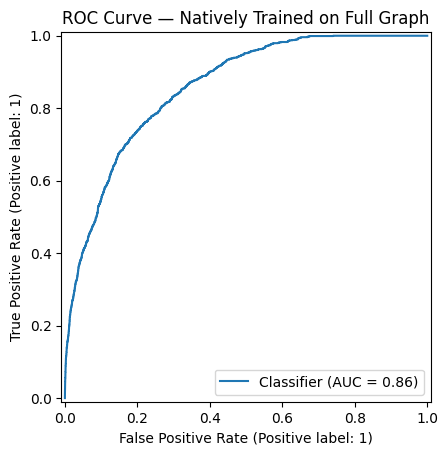

In [ ]:
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title('ROC Curve — Natively Trained on Full Graph')
plt.savefig(f'{DATA_DIR}/full_graph_native_roc.png', dpi=150, bbox_inches='tight')
plt.show()


## 4. Feature importance — does it still lean on the same signals?

Worth checking whether PageRank/community features are still the top drivers at this
scale, or whether the ranking shifts once trained on the full graph natively.


community_laundering_rate    0.247054
total_received               0.128501
total_sent                   0.126147
pagerank                     0.107459
n_received_txns              0.090066
n_sent_txns                  0.084156
in_degree                    0.081408
community_size               0.070466
out_degree                   0.064744
dtype: float64


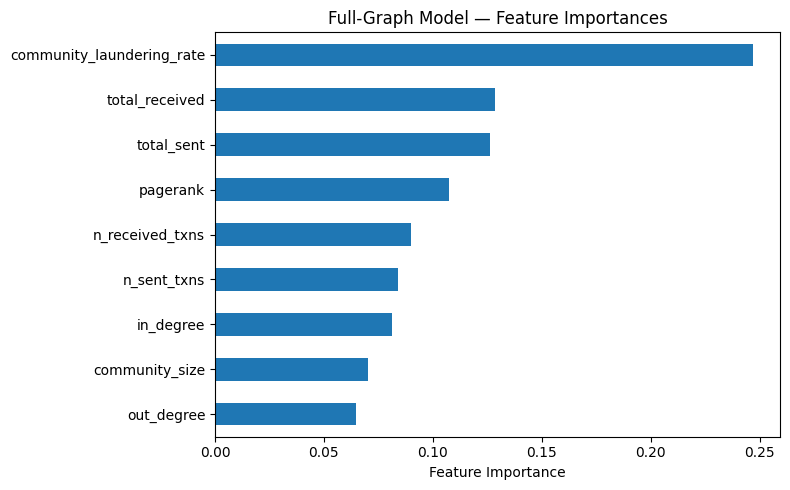

In [ ]:
importances = pd.Series(rf_full.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(importances)

plt.figure(figsize=(8, 5))
importances.plot(kind='barh')
plt.gca().invert_yaxis()
plt.xlabel('Feature Importance')
plt.title('Full-Graph Model — Feature Importances')
plt.tight_layout()
plt.savefig(f'{DATA_DIR}/full_graph_native_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
import joblib
joblib.dump(rf_full, f'{DATA_DIR}/HI-Small_rf_model_fullgraph.pkl')
print('Saved full-graph-native model to Drive.')


Saved full-graph-native model to Drive.


# AML Graph Project — Step 6a: Prepare Streaming Sample for the Live Dashboard

 Streaming all 5M transactions wouldn't be
practical for a live demo, so this keeps **every laundering transaction** plus a **random
sample of normal transactions** from the same time range — small enough to stream smoothly,
while still containing every real alert case.



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

DATA_DIR = '/content/drive/MyDrive/aml_data'

merged = pd.read_parquet(f'{DATA_DIR}/HI-Small_merged_timeline.parquet')
merged['sender_node'] = merged['From_Bank'].astype(str) + '_' + merged['Account']
merged['receiver_node'] = merged['To_Bank'].astype(str) + '_' + merged['Account.1']

risk_df = pd.read_csv(f'{DATA_DIR}/HI-Small_risk_scores.csv')
risk_lookup = risk_df.set_index('node')['risk_score'].to_dict()

print('Transactions:', merged.shape)
print('Accounts with a precomputed risk score:', len(risk_lookup))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Transactions: (5078336, 23)
Accounts with a precomputed risk score: 64067


In [ ]:
SAMPLE_MULTIPLIER = 5
MAX_ROWS = 20000

laundering_txns = merged[merged['Is_Laundering'] == 1]
n_legit_to_sample = min(len(laundering_txns) * SAMPLE_MULTIPLIER, MAX_ROWS - len(laundering_txns))

legit_sample = merged[merged['Is_Laundering'] == 0].sample(n=n_legit_to_sample, random_state=42)

replay_sample = pd.concat([laundering_txns, legit_sample]).sort_values('Timestamp').reset_index(drop=True)

print(f'Replay sample: {len(replay_sample)} rows '
      f'({laundering_txns.shape[0]} laundering, {n_legit_to_sample} legitimate)')


Replay sample: 20000 rows (5177 laundering, 14823 legitimate)


In [ ]:
DEFAULT_SCORE = 0.02

replay_sample['sender_risk_score'] = replay_sample['sender_node'].map(risk_lookup).fillna(DEFAULT_SCORE)
replay_sample['receiver_risk_score'] = replay_sample['receiver_node'].map(risk_lookup).fillna(DEFAULT_SCORE)
replay_sample['txn_risk_score'] = replay_sample[['sender_risk_score', 'receiver_risk_score']].max(axis=1)

dashboard_cols = [
    'Timestamp', 'sender_node', 'receiver_node', 'Amount_Paid', 'Payment_Currency',
    'Payment_Format', 'Is_Laundering', 'sender_risk_score', 'receiver_risk_score', 'txn_risk_score'
]
replay_sample = replay_sample[dashboard_cols].sort_values('Timestamp').reset_index(drop=True)

print(replay_sample.head(10))
print(f"\nHigh-risk (score > 0.5) transactions in sample: {(replay_sample['txn_risk_score'] > 0.5).sum()}")


   Timestamp       sender_node     receiver_node   Amount_Paid  \
0 2022-09-01  232073_80BB34120  232073_80BB34120    550.970000   
1 2022-09-01  110603_809658E30  113779_80BC968A0  35303.920000   
2 2022-09-01     126_813427C01  152416_813B193D1      0.002722   
3 2022-09-01     119_8123F9BF0     119_8123F9BF0  14767.470000   
4 2022-09-01    6625_8031CBA00    6625_8031CBA00     20.460000   
5 2022-09-01  149706_812E524E0    5329_807D79200    152.640000   
6 2022-09-01  324836_8095859A0   25534_809585950   3540.120000   
7 2022-09-01    2915_800930930    2915_800930930     16.500000   
8 2022-09-01   11657_80775CBB0   11657_80775CBB0      9.030000   
9 2022-09-01  328028_80A921E00  328028_80A921E00    331.030000   

    Payment_Currency Payment_Format  Is_Laundering  sender_risk_score  \
0               Euro   Reinvestment              0           0.020000   
1          US Dollar         Cheque              0           0.008343   
2            Bitcoin        Bitcoin              0    

In [ ]:
OUT_PATH = f'{DATA_DIR}/HI-Small_streaming_sample.csv'
replay_sample.to_csv(OUT_PATH, index=False)
print('Saved to', OUT_PATH)
print('\nDownload this file (and HI-Small_risk_scores.csv) to your computer, next to app.py,')
print('before running the Streamlit dashboard.')


Saved to /content/drive/MyDrive/aml_data/HI-Small_streaming_sample.csv

Download this file (and HI-Small_risk_scores.csv) to your computer, next to app.py,
before running the Streamlit dashboard.


# AML Graph Project — Model Comparison (RF vs XGBoost vs Logistic Regression)

Benchmarks your existing Random Forest against XGBoost and Logistic Regression on the exact
same graph-derived feature table from Step 4, so the comparison is fair (same features, same
train/test split, same evaluation metrics).


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import networkx as nx
import pickle

DATA_DIR = '/content/drive/MyDrive/aml_data'

# Rebuild exactly as in Step 4
G_agg = nx.read_graphml(f'{DATA_DIR}/HI-Small_agg_graph.graphml')
G_clean = G_agg.copy()
G_clean.remove_edges_from(list(nx.selfloop_edges(G_clean)))
G_clean.remove_nodes_from(list(nx.isolates(G_clean)))

laundering_nodes = set()
for u, v, d in G_clean.edges(data=True):
    if int(d.get('any_laundering', 0)) == 1:
        laundering_nodes.add(u); laundering_nodes.add(v)

expanded_nodes = set(laundering_nodes)
for n in laundering_nodes:
    expanded_nodes.update(G_clean.predecessors(n))
    expanded_nodes.update(G_clean.successors(n))

G_sub = G_clean.subgraph(expanded_nodes).copy()

risk_df = pd.read_csv(f'{DATA_DIR}/HI-Small_risk_scores.csv')
with open(f'{DATA_DIR}/HI-Small_communities.pkl', 'rb') as f:
    comm_data = pickle.load(f)
communities, node_to_comm = comm_data['communities'], comm_data['node_to_comm']

sent_amount, recv_amount, sent_count, recv_count = {}, {}, {}, {}
for u, v, d in G_sub.edges(data=True):
    sent_amount[u] = sent_amount.get(u, 0) + d.get('total_amount', 0)
    recv_amount[v] = recv_amount.get(v, 0) + d.get('total_amount', 0)
    sent_count[u] = sent_count.get(u, 0) + d.get('n_transactions', 0)
    recv_count[v] = recv_count.get(v, 0) + d.get('n_transactions', 0)

comm_edge_totals, comm_edge_flagged = {}, {}
for u, v, d in G_sub.edges(data=True):
    cid = node_to_comm.get(u)
    comm_edge_totals[cid] = comm_edge_totals.get(cid, 0) + 1
    if int(d.get('any_laundering', 0)) == 1:
        comm_edge_flagged[cid] = comm_edge_flagged.get(cid, 0) + 1
comm_rate = {c: comm_edge_flagged.get(c, 0) / t for c, t in comm_edge_totals.items()}

rows = []
for n in G_sub.nodes():
    cid = node_to_comm.get(n)
    rows.append({
        'node': n, 'in_degree': G_sub.in_degree(n), 'out_degree': G_sub.out_degree(n),
        'total_sent': sent_amount.get(n, 0), 'total_received': recv_amount.get(n, 0),
        'n_sent_txns': sent_count.get(n, 0), 'n_received_txns': recv_count.get(n, 0),
        'community_laundering_rate': comm_rate.get(cid, 0),
        'community_size': len(communities[cid]) if cid is not None else 0,
        'label': int(n in laundering_nodes),
    })
feature_df = pd.DataFrame(rows).merge(risk_df[['node', 'pagerank']], on='node', how='left')
print('Feature table:', feature_df.shape)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Feature table: (64067, 11)


In [ ]:
from sklearn.model_selection import train_test_split

feature_cols = ['in_degree', 'out_degree', 'pagerank', 'total_sent', 'total_received',
                 'n_sent_txns', 'n_received_txns', 'community_laundering_rate', 'community_size']

X = feature_df[feature_cols].fillna(0)
y = feature_df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)


Train: (51253, 9) | Test: (12814, 9)


## 3. Train all three models

- **Random Forest**: your existing Step 4 model type, retrained here on the same feature set for an apples-to-apples comparison
- **XGBoost**: gradient boosting, the model type used in our base paper (GFP)
- **Logistic Regression**: a simple linear baseline, to show how much the tree-based models actually gain from non-linearity


In [ ]:
!pip install xgboost -q


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score

models = {}

models['Random Forest'] = RandomForestClassifier(
    n_estimators=300, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1
).fit(X_train, y_train)

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
models['XGBoost'] = XGBClassifier(
    n_estimators=300, max_depth=6, scale_pos_weight=scale_pos_weight,
    eval_metric='logloss', random_state=42, n_jobs=-1
).fit(X_train, y_train)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
models['Logistic Regression'] = LogisticRegression(
    class_weight='balanced', max_iter=1000, random_state=42
).fit(X_train_scaled, y_train)

print('All three models trained.')


All three models trained.


## 4. Evaluate and compare

In [ ]:
results = []
for name, model in models.items():
    X_eval = X_test_scaled if name == 'Logistic Regression' else X_test
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)[:, 1]
    report = classification_report(y_test, y_pred, output_dict=True)
    results.append({
        'Model': name,
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'Precision (laundering)': report['1']['precision'],
        'Recall (laundering)': report['1']['recall'],
        'F1 (laundering)': report['1']['f1-score'],
    })

results_df = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False)
print(results_df.to_string(index=False))


              Model  ROC-AUC  Precision (laundering)  Recall (laundering)  F1 (laundering)
      Random Forest 0.963775                0.664304             0.811172         0.730429
            XGBoost 0.958955                0.635468             0.811959         0.712953
Logistic Regression 0.916274                0.432088             0.800944         0.561345


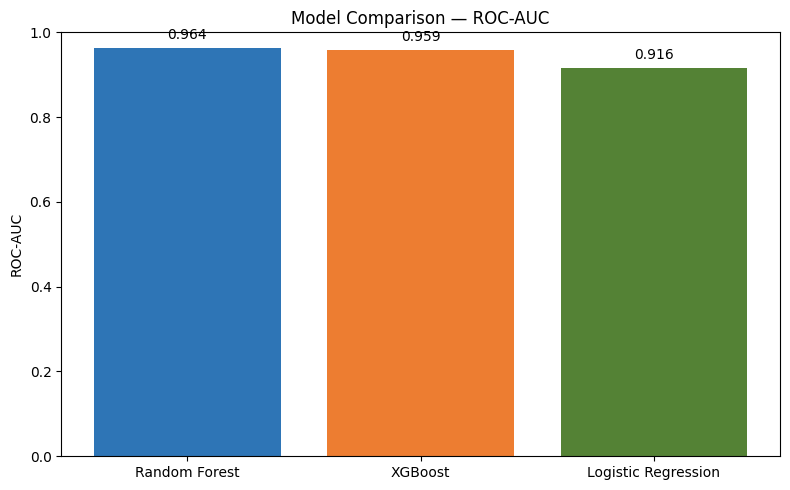

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
x = range(len(results_df))
ax.bar(x, results_df['ROC-AUC'], color=['#2E75B6', '#ED7D31', '#548235'])
ax.set_xticks(x)
ax.set_xticklabels(results_df['Model'])
ax.set_ylabel('ROC-AUC')
ax.set_ylim(0, 1)
ax.set_title('Model Comparison — ROC-AUC')
for i, v in enumerate(results_df['ROC-AUC']):
    ax.text(i, v + 0.02, f'{v:.3f}', ha='center')
plt.tight_layout()
plt.savefig(f'{DATA_DIR}/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
results_df.to_csv(f'{DATA_DIR}/HI-Small_model_comparison.csv', index=False)
print('Saved model comparison results to Drive.')


Saved model comparison results to Drive.


# AML Graph Project — SHAP Explainability

Adds per-account explainability to your Step 4 Random Forest model using SHAP (SHapley
Additive exPlanations). Unlike global feature importance (which only tells you "PageRank
matters most on average"), SHAP tells you *why a specific account* was flagged — which is
what an AML analyst actually needs to justify an alert.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install shap -q

import pandas as pd
import numpy as np
import networkx as nx
import pickle
import joblib
import shap

DATA_DIR = '/content/drive/MyDrive/aml_data'

rf_model = joblib.load(f'{DATA_DIR}/HI-Small_rf_model.pkl')
risk_df = pd.read_csv(f'{DATA_DIR}/HI-Small_risk_scores.csv')
print('Loaded model and risk scores.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded model and risk scores.


In [ ]:
# Rebuild the exact Step 4 feature table (same features the model was trained on)
G_agg = nx.read_graphml(f'{DATA_DIR}/HI-Small_agg_graph.graphml')
G_clean = G_agg.copy()
G_clean.remove_edges_from(list(nx.selfloop_edges(G_clean)))
G_clean.remove_nodes_from(list(nx.isolates(G_clean)))

laundering_nodes = set()
for u, v, d in G_clean.edges(data=True):
    if int(d.get('any_laundering', 0)) == 1:
        laundering_nodes.add(u); laundering_nodes.add(v)

expanded_nodes = set(laundering_nodes)
for n in laundering_nodes:
    expanded_nodes.update(G_clean.predecessors(n))
    expanded_nodes.update(G_clean.successors(n))

G_sub = G_clean.subgraph(expanded_nodes).copy()

with open(f'{DATA_DIR}/HI-Small_communities.pkl', 'rb') as f:
    comm_data = pickle.load(f)
communities, node_to_comm = comm_data['communities'], comm_data['node_to_comm']

sent_amount, recv_amount, sent_count, recv_count = {}, {}, {}, {}
for u, v, d in G_sub.edges(data=True):
    sent_amount[u] = sent_amount.get(u, 0) + d.get('total_amount', 0)
    recv_amount[v] = recv_amount.get(v, 0) + d.get('total_amount', 0)
    sent_count[u] = sent_count.get(u, 0) + d.get('n_transactions', 0)
    recv_count[v] = recv_count.get(v, 0) + d.get('n_transactions', 0)

comm_edge_totals, comm_edge_flagged = {}, {}
for u, v, d in G_sub.edges(data=True):
    cid = node_to_comm.get(u)
    comm_edge_totals[cid] = comm_edge_totals.get(cid, 0) + 1
    if int(d.get('any_laundering', 0)) == 1:
        comm_edge_flagged[cid] = comm_edge_flagged.get(cid, 0) + 1
comm_rate = {c: comm_edge_flagged.get(c, 0) / t for c, t in comm_edge_totals.items()}

nodes_in_cycle = set()  # optional — left empty unless you re-run Step 3 cycle detection

rows = []
for n in G_sub.nodes():
    cid = node_to_comm.get(n)
    rows.append({
        'node': n, 'in_degree': G_sub.in_degree(n), 'out_degree': G_sub.out_degree(n),
        'total_sent': sent_amount.get(n, 0), 'total_received': recv_amount.get(n, 0),
        'n_sent_txns': sent_count.get(n, 0), 'n_received_txns': recv_count.get(n, 0),
        'in_any_cycle': int(n in nodes_in_cycle), 'in_flagged_cycle': int(n in nodes_in_cycle),
        'community_laundering_rate': comm_rate.get(cid, 0),
        'community_size': len(communities[cid]) if cid is not None else 0,
        'label': int(n in laundering_nodes),
    })
feature_df = pd.DataFrame(rows).merge(risk_df[['node', 'pagerank']], on='node', how='left')

feature_cols = ['in_degree', 'out_degree', 'pagerank', 'total_sent', 'total_received',
                 'n_sent_txns', 'n_received_txns', 'in_any_cycle', 'in_flagged_cycle',
                 'community_laundering_rate', 'community_size']
X = feature_df[feature_cols].fillna(0)
print('Feature table ready:', X.shape)


Feature table ready: (64067, 11)


## 2. Compute SHAP values

`TreeExplainer` is fast and exact for tree-based models like Random Forest. We compute SHAP
values on a sample (not the full 64K accounts) to keep this quick — 2,000 accounts is plenty
for both the summary plot and individual explanations.


In [ ]:
SAMPLE_SIZE = 2000
sample_idx = X.sample(n=min(SAMPLE_SIZE, len(X)), random_state=42).index
X_sample = X.loc[sample_idx]

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_sample)

# For binary classifiers, shap_values may be a list [class_0, class_1] or a single array
# depending on the sklearn/shap version — normalize to the "laundering" class array
if isinstance(shap_values, list):
    shap_values_pos = shap_values[1]
else:
    shap_values_pos = shap_values

print('SHAP values computed for', X_sample.shape[0], 'accounts.')


SHAP values computed for 2000 accounts.


## 3. Global summary plot

Similar to Step 4's feature importance chart, but richer: shows not just *which* features
matter, but *which direction* they push the prediction (red = pushes toward "laundering",
blue = pushes toward "not laundering") and how that varies by feature value.


/tmp/ipykernel_4786/3164494240.py:12: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_pos, X_sample, show=False)


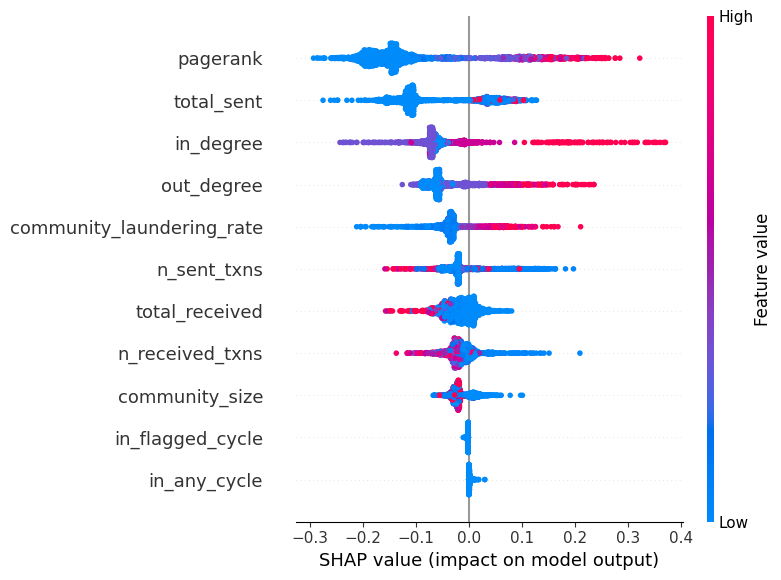

In [ ]:
import matplotlib.pyplot as plt

# Handle both old (list) and new (3D array) SHAP output formats robustly
sv = explainer.shap_values(X_sample)
if isinstance(sv, list):
    shap_values_pos = sv[1]
elif sv.ndim == 3:
    shap_values_pos = sv[:, :, 1]
else:
    shap_values_pos = sv

shap.summary_plot(shap_values_pos, X_sample, show=False)
plt.tight_layout()
plt.savefig(f'{DATA_DIR}/shap_summary_plot.png', dpi=150, bbox_inches='tight')
plt.show()

Explaining account: 28_80A4273C0 (risk score: 0.999)


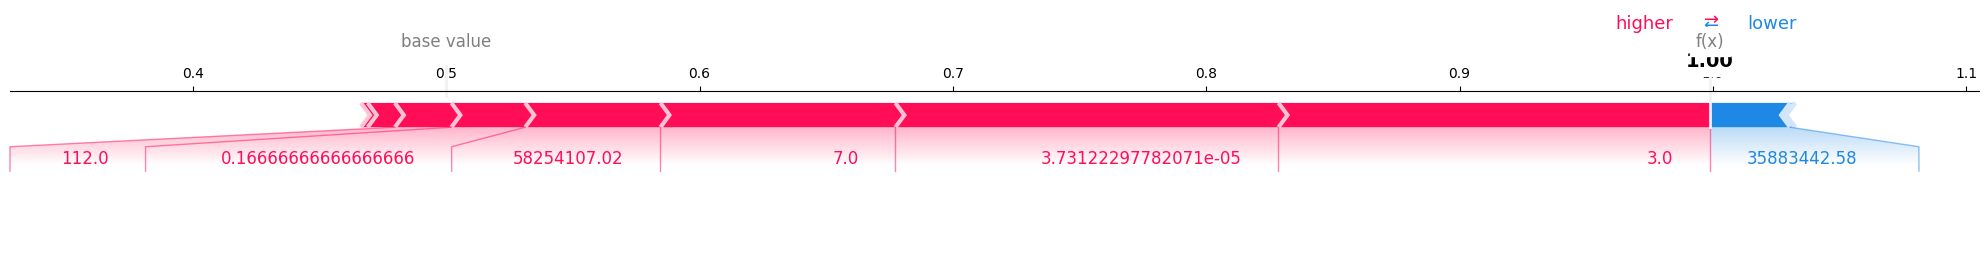

In [ ]:
X_sample_with_risk = X_sample.copy()
X_sample_with_risk['node'] = feature_df.loc[sample_idx, 'node'].values
X_sample_with_risk['risk_score'] = rf_model.predict_proba(X_sample)[:, 1]

top_account_pos = X_sample_with_risk['risk_score'].values.argmax()
top_account = X_sample_with_risk.iloc[top_account_pos]
print(f"Explaining account: {top_account['node']} (risk score: {top_account['risk_score']:.3f})")

# Re-compute SHAP values for the single top account to avoid the NotImplementedError
X_single_instance_df = X_sample.iloc[[top_account_pos]] # Keep as DataFrame for explainer
shap_values_single_instance = explainer.shap_values(X_single_instance_df)

# Extract the SHAP values for the positive class (index 1) for this single sample
# explainer.shap_values returns a list of arrays (num_samples, num_features) for multi-output,
# or a single array (num_samples, num_features) for single-output,
# or sometimes a 3D array (num_samples, num_classes, num_features) for multi-class output
if isinstance(shap_values_single_instance, list):
    # If it's a list, it's [shap_values_class0, shap_values_class1]
    # Each item in the list is (num_samples, num_features). We need the first sample for class 1.
    shap_values_for_plot = shap_values_single_instance[1][0]
else:
    # If it's a numpy array, it can be (num_samples, num_features) or (num_samples, num_classes, num_features).
    # Based on the kernel state, it's likely (1, num_features, num_classes).
    # We need the positive class (index 1) for the first (and only) sample, across all features.
    shap_values_for_plot = shap_values_single_instance[0, :, 1] # Get first sample's values for the positive class, all features

# The features for plotting should also be a 1D array
features_for_plot = X_sample.iloc[top_account_pos].values

# The base value (expected_value) for the positive class
base_value_for_plot = explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value

shap.force_plot(
    base_value_for_plot,
    shap_values_for_plot,
    features_for_plot,
    matplotlib=True, show=False
)
plt.tight_layout()
plt.savefig(f'{DATA_DIR}/shap_force_plot_top_account.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
contributions = pd.Series(shap_values_pos[top_account_pos], index=feature_cols).sort_values(key=abs, ascending=False)
print(f"Top factors driving the risk score for account {top_account['node']}:\n")
for feat, val in contributions.head(5).items():
    direction = 'increased' if val > 0 else 'decreased'
    print(f'  {feat}: {direction} risk score by {abs(val):.4f}')

Top factors driving the risk score for account 28_80A4273C0:

  in_degree: increased risk score by 0.1704
  pagerank: increased risk score by 0.1512
  out_degree: increased risk score by 0.0927
  total_sent: increased risk score by 0.0534
  total_received: decreased risk score by 0.0316


In [ ]:
shap_df = pd.DataFrame(shap_values_pos, columns=feature_cols)
shap_df['node'] = feature_df.loc[sample_idx, 'node'].values
shap_df.to_csv(f'{DATA_DIR}/HI-Small_shap_values_sample.csv', index=False)
print('Saved SHAP values to Drive.')

Saved SHAP values to Drive.
